# Human Activity Recognition Using Hidden Markov Models

## 1. Background and Motivation

This project investigates a smartphone-based campus fitness tracker that distinguishes standing, walking, jumping, and still periods. Recognizing these activities could help students understand their movement during exercise sessions while distinguishing a stationary phone from one held by a standing person. We use recorded accelerometer and gyroscope signals to extract time-domain and frequency-domain features, then train a Hidden Markov Model (HMM) to recognize activity sequences. Performance will be evaluated on separate, unseen recordings using sensitivity, specificity, and accuracy.

In [1]:
from pathlib import Path
from zipfile import ZipFile
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT = Path("/content/activity_hmm")
RAW = PROJECT / "data" / "raw"
REPORT = PROJECT / "report_assets"
ZIP_PATH = Path("/content/Human_Activity_Recordings.zip")

REPORT.mkdir(parents=True, exist_ok=True)

assert ZIP_PATH.exists(), "Upload Human_Activity_Recordings.zip first."

with ZipFile(ZIP_PATH) as archive:
    for name in archive.namelist():
        if not (RAW / name).resolve().is_relative_to(RAW.resolve()):
            raise ValueError("The ZIP contains an invalid file path.")
    archive.extractall(RAW)

DATA = RAW / "Human_Activity_Recordings"
ACTIVITIES = ["standing", "walking", "still", "jumping"]

recordings = sorted(
    folder for folder in DATA.iterdir()
    if folder.is_dir()
    and folder.name.split("-")[0].lower() in ACTIVITIES
)

counts = Counter(
    folder.name.split("-")[0].lower() for folder in recordings
)

for activity in ACTIVITIES:
    print(f"{activity.capitalize()}: {counts[activity]}")

print(f"\nTotal recordings: {len(recordings)}")

Standing: 13
Walking: 13
Still: 12
Jumping: 12

Total recordings: 50


### Recording Inventory

The dataset contains 50 recordings: 13 standing, 13 walking, 12 still, and 12 jumping. All four required activities are represented, with nearly equal recording counts.

In [2]:
example = next(
    folder for folder in recordings
    if folder.name.lower().startswith("standing-1-")
)

print(f"Recording: {example.name}\n")

rows = []

for path in sorted(example.glob("*.csv")):
    if path.stat().st_size == 0:
        rows.append({
            "File": path.name,
            "Rows": 0,
            "Columns": "Empty file"
        })
    else:
        frame = pd.read_csv(path)

        rows.append({
            "File": path.name,
            "Rows": len(frame),
            "Columns": ", ".join(frame.columns)
        })

display(pd.DataFrame(rows))

Recording: standing-1-2026-10-28_14-38-34



,File,Rows,Columns
0,Accelerometer.csv,479,"time, seconds_elapsed, z, y, x"
1,AccelerometerUncalibrated.csv,0,Empty file
2,Annotation.csv,0,Empty file
3,Gravity.csv,479,"time, seconds_elapsed, z, y, x"
4,Gyroscope.csv,480,"time, seconds_elapsed, z, y, x"
5,GyroscopeUncalibrated.csv,480,"time, seconds_elapsed, z, y, x"
6,Metadata.csv,1,"version, device name, recording epoch time, re..."
7,TotalAcceleration.csv,480,"time, seconds_elapsed, z, y, x"


### Recording Structure

The inspected standing recording contains timestamped acceleration and gyroscope measurements on all three axes. Two auxiliary files are empty. Sensor row counts differ slightly, so timestamp alignment will be checked before combining the signals. This inspection covers one recording; dataset-wide quality checks follow.

In [3]:
SENSOR_FILES = [
    "Accelerometer.csv",
    "TotalAcceleration.csv",
    "Gyroscope.csv"
]

REQUIRED_COLUMNS = ["time", "seconds_elapsed", "x", "y", "z"]
audit_rows = []

for folder in recordings:
    activity = folder.name.split("-")[0].lower()

    for sensor in SENSOR_FILES:
        path = folder / sensor
        result = {
            "recording": folder.name,
            "activity": activity,
            "sensor": sensor
        }

        try:
            frame = pd.read_csv(path)

            if not set(REQUIRED_COLUMNS).issubset(frame.columns):
                raise ValueError("Required columns are missing.")

            values = frame[REQUIRED_COLUMNS].apply(
                pd.to_numeric, errors="coerce"
            )

            if len(values) < 2:
                raise ValueError("Fewer than two sensor samples.")

            elapsed = values["seconds_elapsed"]
            intervals = elapsed.diff().dropna()
            positive_intervals = intervals[intervals > 0]

            result.update({
                "status": "read",
                "rows": len(values),
                "duration_s": elapsed.iloc[-1] - elapsed.iloc[0],
                "sampling_hz": (
                    1 / positive_intervals.median()
                    if len(positive_intervals) else np.nan
                ),
                "invalid_values": int(
                    (~np.isfinite(values.to_numpy())).sum()
                ),
                "duplicate_times": int(elapsed.duplicated().sum()),
                "nonincreasing_times": int((intervals <= 0).sum()),
                "gaps_over_100ms": int((intervals > 0.1).sum())
            })

        except Exception as error:
            result["status"] = str(error)

        audit_rows.append(result)

audit = pd.DataFrame(audit_rows)
audit.to_csv(REPORT / "sensor_audit.csv", index=False)

print("Sensor files inspected:", len(audit))
print("\nFile status:")
display(audit["status"].value_counts().to_frame("files"))

print("\nTiming summary:")
display(
    audit.groupby("sensor").agg(
        files=("recording", "size"),
        shortest_s=("duration_s", "min"),
        longest_s=("duration_s", "max"),
        lowest_hz=("sampling_hz", "min"),
        highest_hz=("sampling_hz", "max")
    ).round(3)
)

print("\nQuality issues:")
display(
    audit[
        [
            "invalid_values",
            "duplicate_times",
            "nonincreasing_times",
            "gaps_over_100ms"
        ]
    ].sum().to_frame("count")
)

Sensor files inspected: 150

File status:


,files
status,
read,150



Timing summary:


,files,shortest_s,longest_s,lowest_hz,highest_hz
sensor,,,,,
Accelerometer.csv,50,8.881,9.683,49.876,49.876
Gyroscope.csv,50,8.901,9.703,49.876,49.876
TotalAcceleration.csv,50,8.901,9.703,49.876,49.876



Quality issues:


,count
invalid_values,0
duplicate_times,0
nonincreasing_times,0
gaps_over_100ms,0


### Sensor Audit Findings

All 50 recordings contain both acceleration versions and gyroscope data. Sensor durations range from 8.881 to 9.703 seconds, meeting the 5–10-second requirement. Measured sampling rates are approximately 49.876 Hz. No invalid numeric values, duplicate or non-increasing elapsed timestamps, or gaps exceeding 100 ms were detected. These checks support proceeding to sensor alignment; they do not verify activity performance or labels.

In [4]:
coverage_rows = []

for folder in recordings:
    starts, ends = [], []

    for sensor in SENSOR_FILES:
        elapsed = pd.read_csv(
            folder / sensor,
            usecols=["seconds_elapsed"]
        )["seconds_elapsed"]

        starts.append(elapsed.iloc[0])
        ends.append(elapsed.iloc[-1])

    coverage_rows.append({
        "recording": folder.name,
        "activity": folder.name.split("-")[0].lower(),
        "shared_duration_s": min(ends) - max(starts)
    })

coverage = pd.DataFrame(coverage_rows)

summary = (
    coverage.groupby("activity")
    .agg(
        recordings=("recording", "size"),
        total_seconds=("shared_duration_s", "sum"),
        shortest_seconds=("shared_duration_s", "min"),
        longest_seconds=("shared_duration_s", "max")
    )
    .reindex(ACTIVITIES)
)

summary["meets_90_seconds"] = summary["total_seconds"] >= 90

summary.to_csv(REPORT / "dataset_duration_summary.csv")

display(summary.round(3))

,recordings,total_seconds,shortest_seconds,longest_seconds,meets_90_seconds
activity,,,,,
standing,13,119.750,8.980,9.581,True
walking,13,119.405,8.881,9.683,True
still,12,109.420,9.001,9.381,True
jumping,12,108.814,8.901,9.321,True


### Shared Duration Findings

After restricting each recording to the overlapping sensor timelines, standing provides 119.750 seconds, walking 119.405 seconds, still 109.420 seconds, and jumping 108.814 seconds. Every activity exceeds the required 90 seconds, and individual recordings remain within 5–10 seconds. No recordings require exclusion based on these duration checks.

In [5]:
metadata_rows = []

for folder in recordings:
    metadata = pd.read_csv(folder / "Metadata.csv").iloc[0]

    metadata_rows.append({
        "recording": folder.name,
        "phone": metadata.get("device name"),
        "platform": metadata.get("platform"),
        "app_version": metadata.get("appVersion"),
        "sensors": metadata.get("sensors"),
        "intervals_ms": metadata.get("sampleRateMs")
    })

collection_metadata = pd.DataFrame(metadata_rows)

device_summary = (
    collection_metadata
    .groupby(
        ["phone", "platform", "app_version", "sensors", "intervals_ms"],
        dropna=False
    )
    .size()
    .reset_index(name="recordings")
)

collection_metadata.to_csv(
    REPORT / "collection_metadata.csv", index=False
)

display(device_summary)

,phone,platform,app_version,sensors,intervals_ms,recordings
0,SM-M346B,android,1.68,Accelerometer|Gravity|Gyroscope|Annotation|Tot...,20|20|20||20|20|20,50


### Device and Sampling Configuration

All 50 recordings list an SM-M346B Android device running logging-app version 1.68. The motion sensors were configured at 20 ms intervals (50 Hz nominal), while the measured rate was approximately 49.876 Hz. We will align the sensor streams on a common 50 Hz timeline using interpolation within their shared coverage. This small adjustment standardizes timing without adding new measured information.

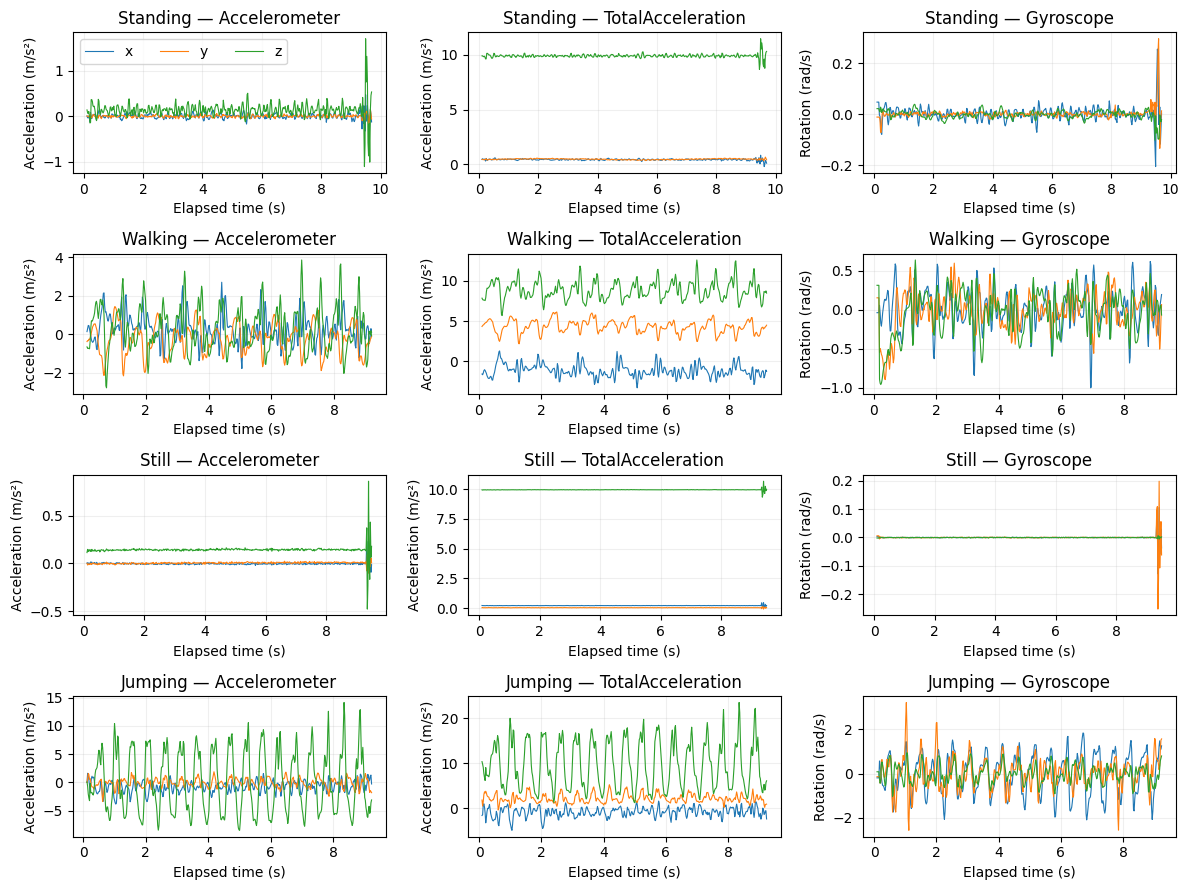

In [6]:
fig, axes = plt.subplots(4, 3, figsize=(12, 9))

for row, activity in enumerate(ACTIVITIES):
    folder = next(
        folder for folder in recordings
        if folder.name.lower().startswith(f"{activity}-1-")
    )

    for column, sensor in enumerate(SENSOR_FILES):
        frame = pd.read_csv(folder / sensor)
        ax = axes[row, column]

        for axis in ["x", "y", "z"]:
            ax.plot(
                frame["seconds_elapsed"],
                frame[axis],
                label=axis,
                linewidth=0.8
            )

        ax.set_title(f"{activity.capitalize()} — {sensor[:-4]}")
        ax.set_xlabel("Elapsed time (s)")
        ax.set_ylabel(
            "Rotation (rad/s)"
            if sensor == "Gyroscope.csv"
            else "Acceleration (m/s²)"
        )
        ax.grid(alpha=0.2)

axes[0, 0].legend(ncol=3)
fig.tight_layout()

fig.savefig(
    REPORT / "raw_sensor_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Initial Signal Observations

The selected recordings show increasing movement from still and standing to walking and jumping. Total acceleration retains a near-gravity offset, whereas the accelerometer signal is centred closer to zero. Sharp changes near the end of the standing and still examples suggest possible stopping-related handling. These observations concern four examples; recording boundaries require further inspection before cleaning.

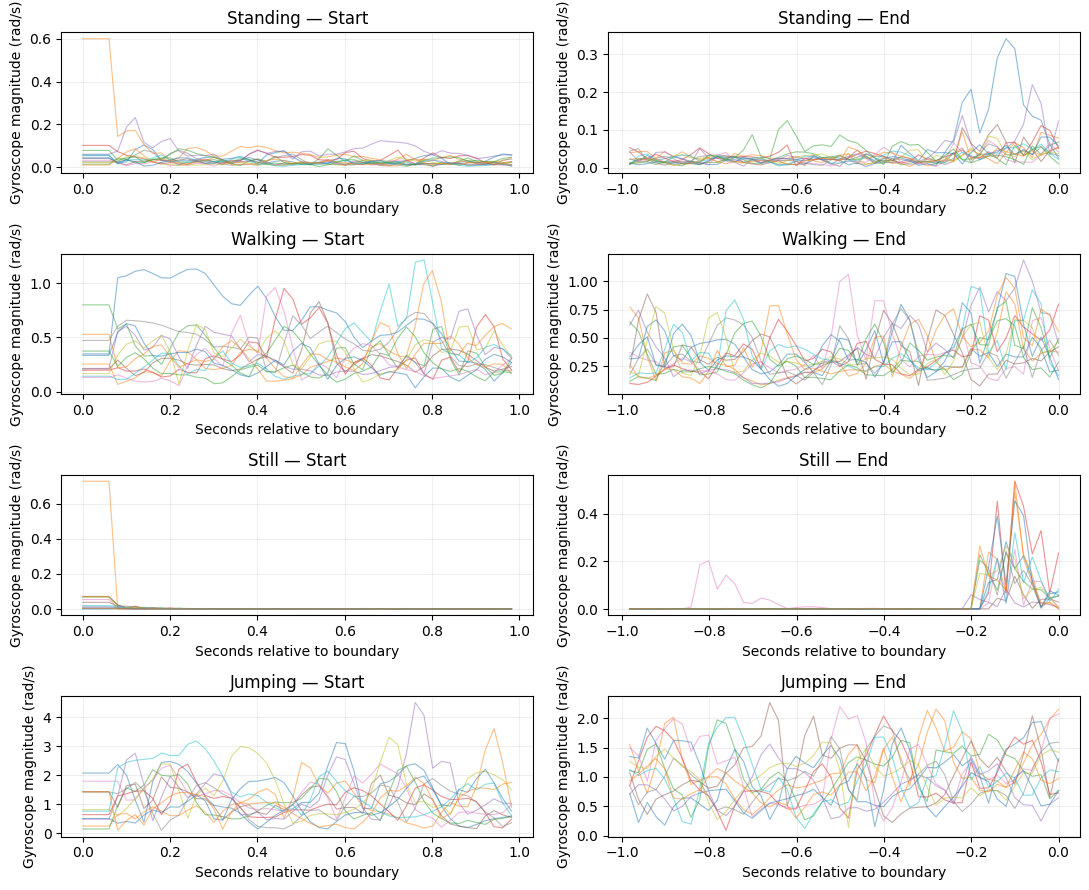

In [7]:
fig, axes = plt.subplots(4, 2, figsize=(11, 9))

for row, activity in enumerate(ACTIVITIES):
    folders = [
        folder for folder in recordings
        if folder.name.split("-")[0].lower() == activity
    ]

    for folder in folders:
        frame = pd.read_csv(folder / "Gyroscope.csv")
        time = frame["seconds_elapsed"]
        magnitude = np.linalg.norm(frame[["x", "y", "z"]], axis=1)

        from_start = time - time.iloc[0]
        before_end = time - time.iloc[-1]

        for column, relative_time in enumerate([from_start, before_end]):
            mask = relative_time.between(0, 1) if column == 0 else (
                relative_time.between(-1, 0)
            )

            axes[row, column].plot(
                relative_time[mask],
                magnitude[mask],
                alpha=0.5,
                linewidth=0.8
            )

    for column, boundary in enumerate(["Start", "End"]):
        ax = axes[row, column]
        ax.set_title(f"{activity.capitalize()} — {boundary}")
        ax.set_xlabel("Seconds relative to boundary")
        ax.set_ylabel("Gyroscope magnitude (rad/s)")
        ax.grid(alpha=0.2)

fig.tight_layout()
fig.savefig(REPORT / "recording_boundaries.png", dpi=300)
plt.show()

### Boundary Inspection and Cleaning Decision

Boundary plots show brief disturbances near the start and end of several stationary recordings. We selected a uniform 0.3-second trim at both ends to reduce possible handling effects while retaining most of each recording. Walking and jumping peaks are treated as activity signals, not automatically removed as outliers. One still recording contains an earlier disturbance requiring separate inspection.

In [8]:
TRIM_SECONDS = 0.3

trimmed_coverage = coverage.copy()
trimmed_coverage["remaining_seconds"] = (
    trimmed_coverage["shared_duration_s"] - 2 * TRIM_SECONDS
)

trim_summary = (
    trimmed_coverage.groupby("activity")
    .agg(
        recordings=("recording", "size"),
        total_seconds=("remaining_seconds", "sum"),
        shortest_seconds=("remaining_seconds", "min"),
        longest_seconds=("remaining_seconds", "max")
    )
    .reindex(ACTIVITIES)
)

trim_summary["meets_90_seconds"] = (
    trim_summary["total_seconds"] >= 90
)

trim_summary["all_recordings_5_to_10s"] = (
    trimmed_coverage.groupby("activity")["remaining_seconds"]
    .apply(lambda durations: durations.between(5, 10).all())
)

display(trim_summary.round(3))

,recordings,total_seconds,shortest_seconds,longest_seconds,meets_90_seconds,all_recordings_5_to_10s
activity,,,,,,
standing,13,111.950,8.380,8.981,True,True
walking,13,111.605,8.281,9.083,True,True
still,12,102.220,8.401,8.781,True,True
jumping,12,101.614,8.301,8.721,True,True


### Duration Check After Proposed Trimming

Removing 0.3 seconds from both ends leaves 8.281–9.083 seconds per recording. All four activities retain more than 90 seconds, so the proposed trim preserves the duration requirements without excluding any recordings. Final durations will be verified again after resampling.

In [9]:
still_rows = []

for folder in recordings:
    if folder.name.split("-")[0].lower() != "still":
        continue

    frame = pd.read_csv(folder / "Gyroscope.csv")

    bounds = coverage.loc[
        coverage["recording"] == folder.name
    ].iloc[0]

    start = max(
        pd.read_csv(folder / sensor)["seconds_elapsed"].iloc[0]
        for sensor in SENSOR_FILES
    ) + TRIM_SECONDS

    end = start + bounds["shared_duration_s"] - 2 * TRIM_SECONDS

    retained = frame.loc[
        frame["seconds_elapsed"].between(start, end)
    ].copy()

    retained["gyro_magnitude"] = np.linalg.norm(
        retained[["x", "y", "z"]], axis=1
    )

    peak = retained.loc[retained["gyro_magnitude"].idxmax()]

    still_rows.append({
        "recording": folder.name,
        "peak_gyro": peak["gyro_magnitude"],
        "seconds_before_trimmed_end": end - peak["seconds_elapsed"]
    })

still_check = (
    pd.DataFrame(still_rows)
    .sort_values("peak_gyro", ascending=False)
    .reset_index(drop=True)
)

display(still_check.round(4))

,recording,peak_gyro,seconds_before_trimmed_end
0,still-4-2026-10-28_15-44-51,0.2030,0.5017
1,still-11-2026-10-28_15-50-18,0.0036,7.6979
2,still-10-2026-10-28_15-43-45,0.0035,8.1604
3,still-5-2026-10-28_15-44-41,0.0032,6.9777
4,still-3-2026-10-28_15-45-01,0.0031,5.2534
5,still-12-2026-10-28_15-49-48,0.0029,2.5062
6,still-7-2026-10-28_15-44-20,0.0029,8.1406
7,still-2-2026-10-28_15-45-12,0.0029,0.9828
8,still-9-2026-10-28_15-43-55,0.0029,0.4619
9,still-6-2026-10-28_15-44-31,0.0028,7.7811


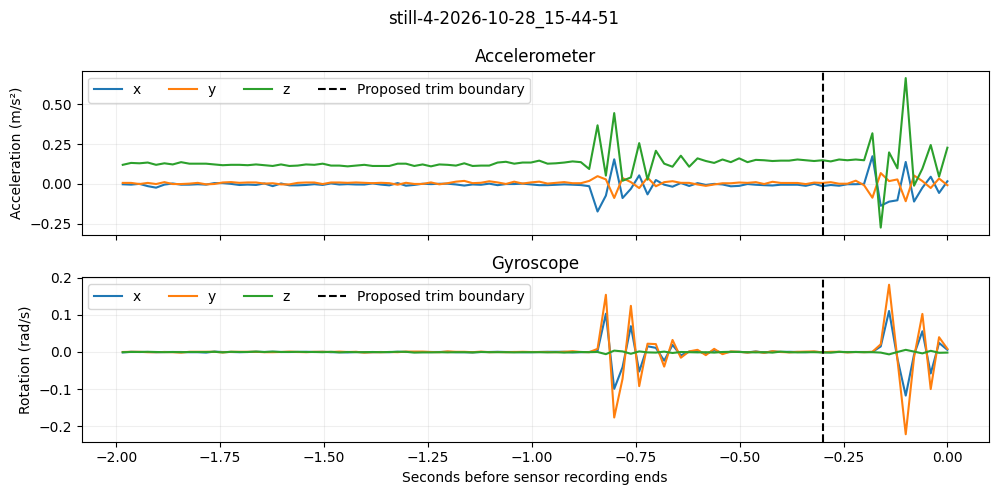

In [10]:
suspect_name = still_check.iloc[0]["recording"]
suspect_folder = DATA / suspect_name

fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True)

for ax, sensor in zip(
    axes, ["Accelerometer.csv", "Gyroscope.csv"]
):
    frame = pd.read_csv(suspect_folder / sensor)

    relative_time = (
        frame["seconds_elapsed"] - frame["seconds_elapsed"].iloc[-1]
    )
    mask = relative_time >= -2

    for axis in ["x", "y", "z"]:
        ax.plot(
            relative_time[mask],
            frame.loc[mask, axis],
            label=axis
        )

    ax.axvline(
        -TRIM_SECONDS,
        color="black",
        linestyle="--",
        label="Proposed trim boundary"
    )

    ax.set_title(sensor.removesuffix(".csv"))
    ax.set_ylabel(
        "Rotation (rad/s)"
        if sensor == "Gyroscope.csv"
        else "Acceleration (m/s²)"
    )
    ax.grid(alpha=0.2)
    ax.legend(ncol=4)

axes[-1].set_xlabel("Seconds before sensor recording ends")
fig.suptitle(suspect_name)
fig.tight_layout()

fig.savefig(
    REPORT / "still_04_disturbance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Recording-Specific Cleaning

The fourth still recording contains simultaneous acceleration and rotation disturbances approximately 0.8 seconds before its end. Its final 1.0 second will therefore be excluded from the cleaned version. All other recordings retain the standard 0.3-second boundary trims. The original files remain unchanged.

In [11]:
cleaning_plan = coverage.copy()

cleaning_plan["start_trim_s"] = 0.3
cleaning_plan["end_trim_s"] = 0.3

cleaning_plan.loc[
    cleaning_plan["recording"] == suspect_name,
    "end_trim_s"
] = 1.0

cleaning_plan["retained_seconds"] = (
    cleaning_plan["shared_duration_s"]
    - cleaning_plan["start_trim_s"]
    - cleaning_plan["end_trim_s"]
)

duration_check = (
    cleaning_plan.groupby("activity")
    .agg(
        recordings=("recording", "size"),
        total_seconds=("retained_seconds", "sum"),
        shortest_seconds=("retained_seconds", "min"),
        longest_seconds=("retained_seconds", "max")
    )
    .reindex(ACTIVITIES)
)

assert cleaning_plan["retained_seconds"].between(5, 10).all()
assert (duration_check["total_seconds"] >= 90).all()

cleaning_plan.to_csv(REPORT / "cleaning_plan.csv", index=False)

display(duration_check.round(3))

,recordings,total_seconds,shortest_seconds,longest_seconds
activity,,,,
standing,13,111.950,8.380,8.981
walking,13,111.605,8.281,9.083
still,12,101.520,7.702,8.781
jumping,12,101.614,8.301,8.721


In [12]:
TARGET_HZ = 50
CLEAN = PROJECT / "data" / "cleaned"
CLEAN.mkdir(parents=True, exist_ok=True)

cleaned_rows = []

for _, plan in cleaning_plan.iterrows():
    folder = DATA / plan["recording"]
    sensors = {
        name: pd.read_csv(folder / name)
        for name in SENSOR_FILES
    }

    start = max(
        frame["seconds_elapsed"].iloc[0]
        for frame in sensors.values()
    ) + plan["start_trim_s"]

    end = min(
        frame["seconds_elapsed"].iloc[-1]
        for frame in sensors.values()
    ) - plan["end_trim_s"]

    sample_count = int(np.floor((end - start) * TARGET_HZ)) + 1
    timeline = start + np.arange(sample_count) / TARGET_HZ

    acceleration = sensors["Accelerometer.csv"]
    origin_ns = int(acceleration["time"].iloc[0])
    origin_s = acceleration["seconds_elapsed"].iloc[0]

    cleaned = pd.DataFrame({
        "timestamp_ns": origin_ns + np.rint(
            (timeline - origin_s) * 1e9
        ).astype("int64"),
        "seconds_elapsed": np.arange(sample_count) / TARGET_HZ
    })

    for filename, prefix in [
        ("Accelerometer.csv", "accel"),
        ("Gyroscope.csv", "gyro")
    ]:
        frame = sensors[filename]

        for axis in ["x", "y", "z"]:
            cleaned[f"{prefix}_{axis}"] = np.interp(
                timeline,
                frame["seconds_elapsed"],
                frame[axis]
            )

    activity = plan["activity"]
    number = int(folder.name.split("-")[1])
    recording_id = f"{activity}_{number:02d}"

    cleaned["activity"] = activity
    cleaned["recording_id"] = recording_id
    cleaned.to_csv(CLEAN / f"{recording_id}.csv", index=False)

    cleaned_rows.append({
        "recording": recording_id,
        "activity": activity,
        "rows": len(cleaned),
        "duration_s": cleaned["seconds_elapsed"].iloc[-1]
    })

cleaned_inventory = pd.DataFrame(cleaned_rows)

assert len(list(CLEAN.glob("*.csv"))) == 50
assert cleaned_inventory["duration_s"].between(5, 10).all()

cleaned_summary = (
    cleaned_inventory.groupby("activity")
    .agg(
        files=("recording", "size"),
        total_seconds=("duration_s", "sum"),
        shortest_seconds=("duration_s", "min"),
        longest_seconds=("duration_s", "max")
    )
    .reindex(ACTIVITIES)
)

assert (cleaned_summary["total_seconds"] >= 90).all()

cleaned_summary.to_csv(REPORT / "cleaned_dataset_summary.csv")

print("Cleaned CSV files:", len(cleaned_inventory))
display(cleaned_summary.round(3))

Cleaned CSV files: 50


,files,total_seconds,shortest_seconds,longest_seconds
activity,,,,
standing,13,111.88,8.38,8.98
walking,13,111.56,8.28,9.08
still,12,101.50,7.70,8.78
jumping,12,101.58,8.30,8.72


In [13]:
sensor_columns = [
    "accel_x", "accel_y", "accel_z",
    "gyro_x", "gyro_y", "gyro_z"
]

validation_rows = []

for path in sorted(CLEAN.glob("*.csv")):
    frame = pd.read_csv(path)
    elapsed_steps = np.diff(frame["seconds_elapsed"])
    timestamp_steps = np.diff(frame["timestamp_ns"])

    validation_rows.append({
        "file": path.name,
        "finite_values": np.isfinite(
            frame[["seconds_elapsed"] + sensor_columns].to_numpy()
        ).all(),
        "uniform_50_hz": np.allclose(
            elapsed_steps, 1 / TARGET_HZ,
            rtol=0, atol=1e-9
        ),
        "valid_timestamps": np.all(
            timestamp_steps == 20_000_000
        ),
        "correct_labels": (
            frame["activity"].eq(path.stem.split("_")[0]).all()
            and frame["recording_id"].eq(path.stem).all()
        )
    })

validation = pd.DataFrame(validation_rows)
checks = validation.drop(columns="file")

display(checks.sum().to_frame("files_passed"))
print(f"All checks passed: {checks.to_numpy().all()}")

validation.to_csv(
    REPORT / "cleaned_file_validation.csv",
    index=False
)

,files_passed
finite_values,50
uniform_50_hz,50
valid_timestamps,50
correct_labels,50


All checks passed: True


### Cleaning Results

Cleaning produced 50 labelled CSV files containing aligned accelerometer and gyroscope measurements at 50 Hz. All files passed numeric, timing, and label-consistency checks. Recording durations range from 7.70 to 9.08 seconds, and every activity retains more than 90 seconds. Original recordings remain unchanged. Label consistency confirms file naming, not independent verification of the performed activity.

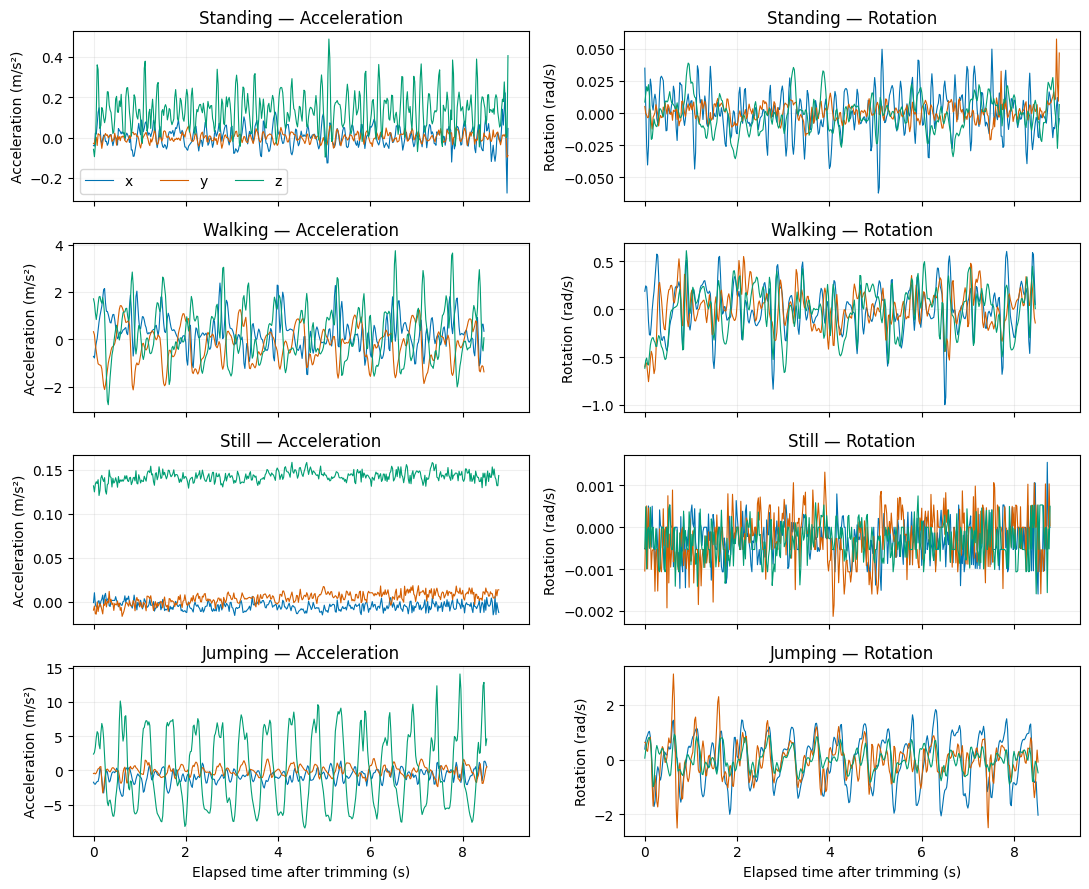

In [14]:
colors = {"x": "#0072B2", "y": "#D55E00", "z": "#009E73"}

fig, axes = plt.subplots(4, 2, figsize=(11, 9), sharex=True)

for row, activity in enumerate(ACTIVITIES):
    frame = pd.read_csv(CLEAN / f"{activity}_01.csv")

    for column, prefix in enumerate(["accel", "gyro"]):
        ax = axes[row, column]

        for axis, color in colors.items():
            ax.plot(
                frame["seconds_elapsed"],
                frame[f"{prefix}_{axis}"],
                color=color,
                label=axis,
                linewidth=0.8
            )

        sensor_name = "Acceleration" if prefix == "accel" else "Rotation"

        ax.set_title(f"{activity.capitalize()} — {sensor_name}")
        ax.set_ylabel(
            "Acceleration (m/s²)"
            if prefix == "accel"
            else "Rotation (rad/s)"
        )
        ax.grid(alpha=0.2)

axes[0, 0].legend(ncol=3)

for ax in axes[-1]:
    ax.set_xlabel("Elapsed time after trimming (s)")

fig.tight_layout()

fig.savefig(
    REPORT / "cleaned_activity_signals.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Cleaned Signal Observations

The cleaned examples retain distinct movement patterns. Still shows minimal rotation, standing contains small fluctuations, walking shows repeated movement, and jumping produces larger acceleration peaks. The prominent boundary disturbances are reduced in the stationary examples. These observations motivate movement-intensity and frequency features, but do not establish classification performance.

## Separate Unseen Test Data

Four additional recordings—standing, walking, still, and jumping—are reserved for final evaluation and stored separately from the development data.

They will receive the same standard preprocessing and feature extraction. Normalization parameters will be fitted on training data only. Test results will not be used to select features, window sizes, or model settings.

Each test recording contains one activity, allowing evaluation of activity recognition but not real activity transitions.

In [15]:
TEST_ZIP = Path("/content/Test_Recordings.zip")
TEST_RAW = PROJECT / "data" / "test_original"

assert TEST_ZIP.exists(), "Upload Test_Recordings.zip first."

with ZipFile(TEST_ZIP) as archive:
    for name in archive.namelist():
        target = (TEST_RAW / name).resolve()

        if not target.is_relative_to(TEST_RAW.resolve()):
            raise ValueError("The ZIP contains an invalid file path.")

    archive.extractall(TEST_RAW)

test_folders = sorted(
    folder for folder in (TEST_RAW / "test_raw").iterdir()
    if folder.is_dir()
)

test_inventory = pd.DataFrame([
    {
        "recording": folder.name,
        "activity": folder.name.split("-")[0].lower(),
        "accelerometer_present": (folder / "Accelerometer.csv").is_file(),
        "gyroscope_present": (folder / "Gyroscope.csv").is_file()
    }
    for folder in test_folders
])

display(test_inventory)
print(f"Total test recordings: {len(test_folders)}")

,recording,activity,accelerometer_present,gyroscope_present
0,jumping-test-2026-10-28_16-46-27,jumping,True,True
1,standing-test-2026-10-28_16-44-30,standing,True,True
2,still-test-2026-10-28_16-46-09,still,True,True
3,walking-test-2026-10-28_16-48-23,walking,True,True


Total test recordings: 4


### Test Data Quality Check

We check the unseen recordings for valid measurements, increasing timestamps, sampling rates, and gaps before preprocessing. These checks assess data integrity; they do not evaluate the model or guide model selection.

In [16]:
test_audit_rows = []

for folder in test_folders:
    for sensor in ["Accelerometer.csv", "Gyroscope.csv"]:
        frame = pd.read_csv(folder / sensor)

        values = frame[REQUIRED_COLUMNS].apply(
            pd.to_numeric, errors="coerce"
        )

        elapsed = values["seconds_elapsed"]
        intervals = np.diff(elapsed)
        positive_intervals = intervals[intervals > 0]

        test_audit_rows.append({
            "activity": folder.name.split("-")[0].lower(),
            "sensor": sensor,
            "rows": len(frame),
            "duration_s": elapsed.iloc[-1] - elapsed.iloc[0],
            "sampling_hz": (
                1 / np.median(positive_intervals)
                if len(positive_intervals) else np.nan
            ),
            "invalid_values": int(
                (~np.isfinite(values.to_numpy())).sum()
            ),
            "nonincreasing_elapsed": int((intervals <= 0).sum()),
            "nonincreasing_timestamps": int(
                (values["time"].diff().dropna() <= 0).sum()
            ),
            "gaps_over_100ms": int((intervals > 0.1).sum())
        })

test_audit = pd.DataFrame(test_audit_rows)

test_audit.to_csv(REPORT / "test_sensor_audit.csv", index=False)

display(test_audit.round(3))

,activity,sensor,rows,duration_s,sampling_hz,invalid_values,nonincreasing_elapsed,nonincreasing_timestamps,gaps_over_100ms
0,jumping,Accelerometer.csv,446,8.922,49.876,0,0,0,0
1,jumping,Gyroscope.csv,447,8.942,49.876,0,0,0,0
2,standing,Accelerometer.csv,459,9.181,49.876,0,0,0,0
3,standing,Gyroscope.csv,460,9.201,49.876,0,0,0,0
4,still,Accelerometer.csv,449,8.983,49.876,0,0,0,0
5,still,Gyroscope.csv,450,9.003,49.876,0,0,0,0
6,walking,Accelerometer.csv,456,9.120,49.876,0,0,0,0
7,walking,Gyroscope.csv,456,9.120,49.876,0,0,0,0


In [17]:
print(test_audit.round(3).to_string(index=False))

activity            sensor  rows  duration_s  sampling_hz  invalid_values  nonincreasing_elapsed  nonincreasing_timestamps  gaps_over_100ms
 jumping Accelerometer.csv   446       8.922       49.876               0                      0                         0                0
 jumping     Gyroscope.csv   447       8.942       49.876               0                      0                         0                0
standing Accelerometer.csv   459       9.181       49.876               0                      0                         0                0
standing     Gyroscope.csv   460       9.201       49.876               0                      0                         0                0
   still Accelerometer.csv   449       8.983       49.876               0                      0                         0                0
   still     Gyroscope.csv   450       9.003       49.876               0                      0                         0                0
 walking Acceleromet

### Test Audit Findings and Preprocessing

All four test recordings contain valid acceleration and gyroscope measurements, with sensor durations between 8.922 and 9.201 seconds. No invalid values, non-increasing timestamps, or gaps exceeding 100 ms were detected. We apply the established 0.3-second boundary trims and 50 Hz sensor alignment, keeping the test files separate from development data.

In [18]:
TEST_CLEAN = PROJECT / "data" / "test_cleaned"
TEST_CLEAN.mkdir(parents=True, exist_ok=True)

test_cleaning_rows = []

for folder in test_folders:
    sensors = {
        name: pd.read_csv(folder / name)
        for name in SENSOR_FILES
    }

    start = max(
        frame["seconds_elapsed"].iloc[0]
        for frame in sensors.values()
    ) + TRIM_SECONDS

    end = min(
        frame["seconds_elapsed"].iloc[-1]
        for frame in sensors.values()
    ) - TRIM_SECONDS

    sample_count = int(np.floor((end - start) * TARGET_HZ)) + 1
    timeline = start + np.arange(sample_count) / TARGET_HZ

    acceleration = sensors["Accelerometer.csv"]
    origin_ns = int(acceleration["time"].iloc[0])
    origin_s = acceleration["seconds_elapsed"].iloc[0]

    cleaned = pd.DataFrame({
        "timestamp_ns": origin_ns + np.rint(
            (timeline - origin_s) * 1e9
        ).astype("int64"),
        "seconds_elapsed": np.arange(sample_count) / TARGET_HZ
    })

    for filename, prefix in [
        ("Accelerometer.csv", "accel"),
        ("Gyroscope.csv", "gyro")
    ]:
        frame = sensors[filename]

        for axis in ["x", "y", "z"]:
            cleaned[f"{prefix}_{axis}"] = np.interp(
                timeline,
                frame["seconds_elapsed"],
                frame[axis]
            )

    activity = folder.name.split("-")[0].lower()
    recording_id = f"{activity}_test"

    cleaned["activity"] = activity
    cleaned["recording_id"] = recording_id

    path = TEST_CLEAN / f"{recording_id}.csv"
    cleaned.to_csv(path, index=False)
    saved = pd.read_csv(path)

    assert np.isfinite(saved[sensor_columns].to_numpy()).all()
    assert np.allclose(
        np.diff(saved["seconds_elapsed"]),
        1 / TARGET_HZ,
        rtol=0,
        atol=1e-9
    )
    assert (np.diff(saved["timestamp_ns"]) == 20_000_000).all()
    assert saved["activity"].eq(activity).all()
    assert saved["recording_id"].eq(recording_id).all()

    duration = saved["seconds_elapsed"].iloc[-1]
    assert 5 <= duration <= 10

    test_cleaning_rows.append({
        "activity": activity,
        "rows": len(saved),
        "duration_s": duration,
        "checks_passed": True
    })

test_cleaned_summary = pd.DataFrame(test_cleaning_rows)

test_cleaned_summary.to_csv(
    REPORT / "test_cleaned_summary.csv", index=False
)

display(test_cleaned_summary.round(3))

,activity,rows,duration_s,checks_passed
0,jumping,417,8.32,True
1,standing,430,8.58,True
2,still,419,8.36,True
3,walking,425,8.48,True


### Test Preprocessing Results

The four test recordings were aligned at 50 Hz after standard boundary trimming. Their retained durations range from 8.32 to 8.58 seconds. All passed numeric, timestamp, sampling-interval, and label-consistency checks. They remain reserved for final evaluation.

## Training and Validation Split

The 50 development recordings are divided into 40 training and 10 validation files. Each activity contributes 10 training files; validation contains three standing, three walking, two still, and two jumping files. Splitting occurs before windowing, keeping overlapping windows from the same recording together. Because these recordings share one participant and collection session, validation measures performance within that collection setting.

In [19]:
SEED = 42
rng = np.random.default_rng(SEED)

validation_counts = {
    "standing": 3,
    "walking": 3,
    "still": 2,
    "jumping": 2
}

split_rows = []

for activity in ACTIVITIES:
    paths = sorted(CLEAN.glob(f"{activity}_*.csv"))
    order = rng.permutation(len(paths))
    count = validation_counts[activity]

    for position, index in enumerate(order):
        split_rows.append({
            "recording_id": paths[index].stem,
            "activity": activity,
            "split": "validation" if position < count else "train",
            "path": str(paths[index])
        })

split_manifest = pd.DataFrame(split_rows)

assert len(split_manifest) == 50
assert split_manifest["recording_id"].is_unique

split_manifest.to_csv(
    PROJECT / "data" / "split_manifest.csv",
    index=False
)

split_summary = pd.crosstab(
    split_manifest["activity"],
    split_manifest["split"]
).reindex(ACTIVITIES)

split_summary.to_csv(REPORT / "development_split_summary.csv")

display(split_summary)
print("\nTotal files per split:")
print(split_manifest["split"].value_counts().to_string())

split,train,validation
activity,,
standing,10,3
walking,10,3
still,10,2
jumping,10,2



Total files per split:
split
train         40
validation    10


## Windowing

Signals are divided into 2-second windows containing 100 samples at 50 Hz. A 1-second step gives 50% overlap and one observation per second. This captures repeated movement while providing 0.5 Hz FFT-bin spacing.

Windows remain within individual recordings and their assigned split. Overlapping windows share samples and are not independent observations. Incomplete trailing windows are excluded. This configuration will be assessed using validation data before final testing.

In [20]:
WINDOW_SECONDS = 2
STEP_SECONDS = 1

WINDOW_SAMPLES = int(WINDOW_SECONDS * TARGET_HZ)
STEP_SAMPLES = int(STEP_SECONDS * TARGET_HZ)

window_rows = []

for recording in split_manifest.itertuples(index=False):
    frame = pd.read_csv(recording.path)

    for start in range(
        0,
        len(frame) - WINDOW_SAMPLES + 1,
        STEP_SAMPLES
    ):
        window_rows.append({
            "recording_id": recording.recording_id,
            "activity": recording.activity,
            "split": recording.split,
            "path": recording.path,
            "start_row": start,
            "stop_row": start + WINDOW_SAMPLES,
            "start_s": frame["seconds_elapsed"].iloc[start]
        })

window_manifest = pd.DataFrame(window_rows)

assert set(window_manifest["recording_id"]) == set(
    split_manifest["recording_id"]
)
assert (
    window_manifest["stop_row"] - window_manifest["start_row"]
).eq(WINDOW_SAMPLES).all()

window_summary = pd.crosstab(
    window_manifest["activity"],
    window_manifest["split"]
).reindex(ACTIVITIES)

window_manifest.to_csv(
    PROJECT / "data" / "window_manifest.csv",
    index=False
)
window_summary.to_csv(REPORT / "window_counts.csv")

display(window_summary)

print("\nWindows per recording:")
display(
    window_manifest.groupby("recording_id")
    .size()
    .agg(["min", "max"])
    .to_frame("windows")
)

split,train,validation
activity,,
standing,70,22
walking,71,21
still,69,14
jumping,70,14



Windows per recording:


,windows
min,6
max,8


## Feature Extraction

Each window produces five features from acceleration and gyroscope signals.

| Feature | Domain | Purpose |
|---|---|---|
| Acceleration magnitude standard deviation | Time | Measures movement variability |
| Centred signal magnitude area (SMA) | Time | Measures acceleration fluctuations across all three axes |
| Gyroscope RMS magnitude | Time | Measures rotation intensity |
| Dominant acceleration frequency | FFT | Captures repeated movement patterns |
| Acceleration spectral energy, 3–10 Hz | FFT | Captures faster variations associated with sharp movements |

Before the FFT, acceleration magnitude is centred and a Hann taper reduces spectral leakage. One-sided spectral power is normalized to account for window length and taper energy. Features will be assessed using development data; their usefulness is not assumed in advance.

In [21]:
FEATURE_NAMES = [
    "acc_std",
    "acc_sma",
    "gyro_rms",
    "dominant_frequency",
    "band_energy_3_10"
]


def extract_features(window):
    acceleration = window[
        ["accel_x", "accel_y", "accel_z"]
    ].to_numpy()

    rotation = window[
        ["gyro_x", "gyro_y", "gyro_z"]
    ].to_numpy()

    magnitude = np.linalg.norm(acceleration, axis=1)
    centred = magnitude - magnitude.mean()

    taper = np.hanning(len(magnitude))
    spectrum = np.fft.rfft(centred * taper)
    frequencies = np.fft.rfftfreq(
        len(magnitude), d=1 / TARGET_HZ
    )

    power = np.abs(spectrum) ** 2
    power /= len(magnitude) * np.sum(taper ** 2)

    if len(magnitude) % 2 == 0:
        power[1:-1] *= 2
    else:
        power[1:] *= 2

    dominant = (
        frequencies[1 + np.argmax(power[1:])]
        if power[1:].sum() > 1e-12 else 0.0
    )

    return {
        "acc_std": magnitude.std(),
        "acc_sma": np.abs(
            acceleration - acceleration.mean(axis=0)
        ).sum(axis=1).mean(),
        "gyro_rms": np.sqrt(np.mean(np.sum(rotation ** 2, axis=1))),
        "dominant_frequency": dominant,
        "band_energy_3_10": power[
            (frequencies >= 3) & (frequencies <= 10)
        ].sum()
    }


feature_rows = []

for path, windows in window_manifest.groupby("path"):
    frame = pd.read_csv(path)

    for window in windows.itertuples(index=False):
        segment = frame.iloc[window.start_row:window.stop_row]

        feature_rows.append({
            "recording_id": window.recording_id,
            "activity": window.activity,
            "split": window.split,
            "start_s": window.start_s,
            **extract_features(segment)
        })

features = pd.DataFrame(feature_rows)

assert len(features) == len(window_manifest)
assert np.isfinite(features[FEATURE_NAMES].to_numpy()).all()

features.to_csv(
    PROJECT / "data" / "development_features.csv",
    index=False
)

training_feature_means = (
    features.loc[features["split"] == "train"]
    .groupby("activity")[FEATURE_NAMES]
    .mean()
    .reindex(ACTIVITIES)
)

training_feature_means.to_csv(
    REPORT / "training_feature_means.csv"
)

print("Feature rows:", len(features))
print("All feature values are finite.")
print(training_feature_means.to_string(float_format=lambda x: f"{x:.4g}"))

Feature rows: 351
All feature values are finite.
          acc_std  acc_sma  gyro_rms  dominant_frequency  band_energy_3_10
activity                                                                  
standing  0.07793   0.1277   0.02333               6.614          0.004804
walking    0.6216    1.845    0.3662               1.599            0.1514
still    0.005778  0.01211   0.00102               4.833         1.092e-05
jumping      2.42    6.632     1.062               3.893             4.961


### Initial Feature Findings

All 351 development windows produced finite feature values. Training averages show increasing acceleration variability, SMA, rotation intensity, and band energy from still to jumping. Dominant frequency requires cautious interpretation because stationary noise and movement harmonics can influence the strongest FFT bin. These averages suggest potential separation but do not establish predictive performance.

## Feature Normalization

The four magnitude/energy features span several orders of magnitude. We apply a log transform to reduce skew, then standardize all five features using training means and population standard deviations. Validation data uses those same parameters. Test data remains untouched, and a small numerical offset permits logging zero values.

In [22]:
LOG_FEATURES = [
    "acc_std",
    "acc_sma",
    "gyro_rms",
    "band_energy_3_10"
]

LOG_OFFSET = 1e-8

transformed = features.copy()

assert (transformed[LOG_FEATURES] >= 0).all().all()

transformed[LOG_FEATURES] = np.log10(
    transformed[LOG_FEATURES] + LOG_OFFSET
)

training_mask = transformed["split"].eq("train")
training_values = transformed.loc[training_mask, FEATURE_NAMES]

feature_means = training_values.mean()
feature_stds = training_values.std(ddof=0)

assert (feature_stds > 1e-12).all(), "A feature has no useful variation."

normalised_features = transformed.copy()
normalised_features[FEATURE_NAMES] = (
    transformed[FEATURE_NAMES] - feature_means
) / feature_stds

assert np.isfinite(
    normalised_features[FEATURE_NAMES].to_numpy()
).all()

scaling_parameters = pd.DataFrame({
    "training_mean": feature_means,
    "training_std": feature_stds,
    "log_transformed": [
        name in LOG_FEATURES for name in FEATURE_NAMES
    ]
})

scaling_parameters.to_csv(REPORT / "scaling_parameters.csv")
normalised_features.to_csv(
    PROJECT / "data" / "normalised_development_features.csv",
    index=False
)

normalization_check = (
    normalised_features.loc[training_mask, FEATURE_NAMES]
    .agg(["mean", lambda values: values.std(ddof=0)])
)

normalization_check.index = ["mean", "std"]

display(normalization_check.round(6))
print("All normalized development values are finite.")

,acc_std,acc_sma,gyro_rms,dominant_frequency,band_energy_3_10
mean,0.0,0.0,-0.0,0.0,0.0
std,1.0,1.0,1.0,1.0,1.0


All normalized development values are finite.


### Normalization Check

All five training features have approximately zero mean and unit population standard deviation after transformation. The same training-fitted parameters were applied to validation data, and all transformed development values are finite.

### Training Feature Distributions

Boxplots summarize each normalized feature by activity. Separation suggests potentially useful features, while overlap indicates possible ambiguity. These plots describe training data only; validation will assess predictive performance.

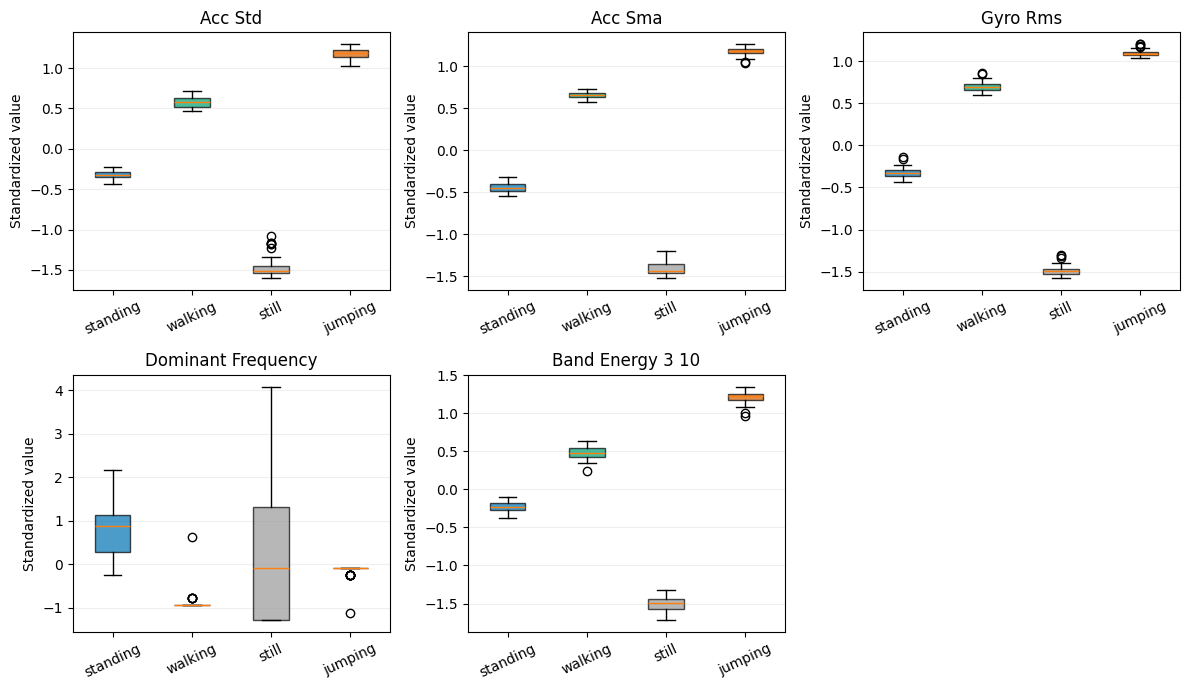

In [23]:
training_features = normalised_features.loc[
    normalised_features["split"].eq("train")
]

activity_colors = ["#0072B2", "#009E73", "#999999", "#D55E00"]

fig, axes = plt.subplots(2, 3, figsize=(12, 7))

for ax, feature in zip(axes.flat, FEATURE_NAMES):
    groups = [
        training_features.loc[
            training_features["activity"].eq(activity),
            feature
        ].to_numpy()
        for activity in ACTIVITIES
    ]

    boxes = ax.boxplot(
        groups,
        patch_artist=True,
        showfliers=True
    )

    for box, color in zip(boxes["boxes"], activity_colors):
        box.set_facecolor(color)
        box.set_alpha(0.7)

    ax.set_xticks(range(1, len(ACTIVITIES) + 1))
    ax.set_xticklabels(ACTIVITIES, rotation=25)
    ax.set_title(feature.replace("_", " ").title())
    ax.set_ylabel("Standardized value")
    ax.grid(axis="y", alpha=0.2)

axes.flat[-1].set_visible(False)

fig.tight_layout()
fig.savefig(
    REPORT / "training_feature_distributions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Feature Distribution Findings

Movement-intensity features show strong separation between activities in the training data. Dominant frequency is less distinct, with broad variation for standing and still. We retain all five features initially and will assess predictive performance using validation data. Boxplot outliers are retained because unusual values do not necessarily indicate recording errors.

## HMM Structure

| Component | Definition |
|---|---|
| Hidden states, Z | Standing, walking, still, jumping |
| Observations, X | Five normalized features per window |
| Initial probabilities, π | Probability of starting in each activity |
| Transition matrix, A | Probability of moving between activity states |
| Emissions, B | Diagonal Gaussian densities describing features within each state |

Baum–Welch will estimate model parameters, using forward–backward calculations. Viterbi will decode the most likely activity sequence. We will compare decoding with emission-only classification to assess its effect on sensitivity, specificity, and accuracy.

Each recording remains a separate sequence. Because the recordings contain single activities, they provide evidence about persistence but limited evidence about real activity changes. Transition regularization will prevent zero-probability paths; it cannot replace observed transitions. The single-activity test recordings also cannot establish transition-detection performance.

In [24]:
STATE_NAMES = ACTIVITIES.copy()
STATE_INDEX = {
    activity: index
    for index, activity in enumerate(STATE_NAMES)
}

sequences = {"train": [], "validation": []}

for split in sequences:
    subset = normalised_features.loc[
        normalised_features["split"].eq(split)
    ]

    for recording_id, group in subset.groupby("recording_id"):
        group = group.sort_values("start_s")
        activity = group["activity"].iloc[0]

        assert group["activity"].nunique() == 1

        sequences[split].append({
            "recording_id": recording_id,
            "activity": activity,
            "state": STATE_INDEX[activity],
            "observations": group[FEATURE_NAMES].to_numpy(),
            "start_s": group["start_s"].to_numpy()
        })

sequence_summary = pd.DataFrame([
    {
        "split": split,
        "sequences": len(items),
        "windows": sum(len(item["observations"]) for item in items),
        "features_per_window": len(FEATURE_NAMES)
    }
    for split, items in sequences.items()
])

sequence_summary.to_csv(REPORT / "sequence_summary.csv", index=False)

display(sequence_summary)
print("State mapping:", STATE_INDEX)

,split,sequences,windows,features_per_window
0,train,40,280,5
1,validation,10,71,5


State mapping: {'standing': 0, 'walking': 1, 'still': 2, 'jumping': 3}


### Model Initialization

The HMM uses four activity states and five continuous features. Initial state probabilities are uniform. Gaussian means are initialized from labelled training windows, anchoring each state to its activity. Initial variances are set to one, allowing Baum–Welch to estimate activity-specific spreads.

The transition matrix starts with a 0.90 probability of remaining in the same state. This is an initialization assumption, not a measured behavior pattern. A variance floor prevents degenerate Gaussian densities. Small transition pseudocounts will regularize training and keep state changes possible; convergence will be assessed using the corresponding penalized objective.

In [25]:
N_STATES = len(STATE_NAMES)
N_FEATURES = len(FEATURE_NAMES)

MIN_VARIANCE = 1e-3
TRANSITION_PSEUDOCOUNT = 0.1

initial_means = np.vstack([
    normalised_features.loc[
        normalised_features["split"].eq("train")
        & normalised_features["activity"].eq(activity),
        FEATURE_NAMES
    ].mean().to_numpy()
    for activity in STATE_NAMES
])

initial_transitions = np.full(
    (N_STATES, N_STATES),
    0.10 / (N_STATES - 1)
)
np.fill_diagonal(initial_transitions, 0.90)

initial_model = {
    "pi": np.full(N_STATES, 1 / N_STATES),
    "A": initial_transitions,
    "means": initial_means,
    "variances": np.ones((N_STATES, N_FEATURES))
}

assert np.isclose(initial_model["pi"].sum(), 1)
assert np.allclose(initial_model["A"].sum(axis=1), 1)
assert np.isfinite(initial_model["means"]).all()
assert (initial_model["variances"] > 0).all()

print("Initial transition matrix:")
display(pd.DataFrame(
    initial_model["A"],
    index=STATE_NAMES,
    columns=STATE_NAMES
).round(4))

print("Initial state probabilities:", initial_model["pi"])
print("Initialization checks passed.")

Initial transition matrix:


,standing,walking,still,jumping
standing,0.9000,0.0333,0.0333,0.0333
walking,0.0333,0.9000,0.0333,0.0333
still,0.0333,0.0333,0.9000,0.0333
jumping,0.0333,0.0333,0.0333,0.9000


Initial state probabilities: [0.25 0.25 0.25 0.25]
Initialization checks passed.


### Gaussian Emissions and Forward–Backward

Each state models the five features using a diagonal Gaussian distribution. This assumes conditional independence between features—an approximation because some movement-intensity features may be correlated.

The forward algorithm calculates sequence likelihood. The backward algorithm supplies future evidence. Together they estimate state probabilities for each window and expected transitions for Baum–Welch. Calculations use log space to reduce numerical underflow. Gaussian emissions are probability densities and may exceed one.

In [26]:
def log_emissions(observations, model):
    differences = observations[:, None, :] - model["means"][None, :, :]
    variances = model["variances"][None, :, :]

    return -0.5 * np.sum(
        np.log(2 * np.pi * variances)
        + differences ** 2 / variances,
        axis=2
    )


def forward_backward(observations, model):
    emissions = log_emissions(observations, model)
    length, states = emissions.shape

    with np.errstate(divide="ignore"):
        log_a = np.log(model["A"])
        log_pi = np.log(model["pi"])

    alpha = np.empty((length, states))
    alpha[0] = log_pi + emissions[0]

    for t in range(1, length):
        alpha[t] = emissions[t] + np.logaddexp.reduce(
            alpha[t - 1][:, None] + log_a,
            axis=0
        )

    likelihood = np.logaddexp.reduce(alpha[-1])
    assert np.isfinite(likelihood), "Sequence likelihood is not finite."

    beta = np.zeros((length, states))

    for t in range(length - 2, -1, -1):
        beta[t] = np.logaddexp.reduce(
            log_a + emissions[t + 1][None, :] + beta[t + 1][None, :],
            axis=1
        )

    gamma = np.exp(alpha + beta - likelihood)

    expected_transitions = np.zeros((states, states))

    for t in range(length - 1):
        expected_transitions += np.exp(
            alpha[t][:, None]
            + log_a
            + emissions[t + 1][None, :]
            + beta[t + 1][None, :]
            - likelihood
        )

    return likelihood, gamma, expected_transitions


example_observations = sequences["train"][0]["observations"]

likelihood, gamma, expected_transitions = forward_backward(
    example_observations, initial_model
)

assert np.isfinite(gamma).all()
assert np.allclose(gamma.sum(axis=1), 1)
assert np.isclose(
    expected_transitions.sum(),
    len(example_observations) - 1
)

print("Windows checked:", len(example_observations))
print("Log-likelihood:", round(float(likelihood), 4))
print("State probabilities sum to one: True")
print("Expected transition count is correct: True")

Windows checked: 7
Log-likelihood: -34.1639
State probabilities sum to one: True
Expected transition count is correct: True


### Viterbi Decoding and Algorithm Verification

Viterbi finds the most likely complete state sequence using log-space calculations and backtracking. We verify it and forward–backward on a synthetic two-state, three-window example. Enumerating all eight possible paths provides independent checks of sequence likelihood, state posteriors, expected transitions, and the best path. This verifies a small case; it is not model evaluation.

In [27]:
from itertools import product


def viterbi(observations, model):
    emissions = log_emissions(observations, model)
    length, states = emissions.shape

    with np.errstate(divide="ignore"):
        log_a = np.log(model["A"])
        log_pi = np.log(model["pi"])

    scores = np.empty((length, states))
    previous = np.zeros((length, states), dtype=int)
    scores[0] = log_pi + emissions[0]

    for t in range(1, length):
        candidates = scores[t - 1][:, None] + log_a
        previous[t] = candidates.argmax(axis=0)
        scores[t] = candidates.max(axis=0) + emissions[t]

    assert np.isfinite(scores[-1].max()), "No valid state path."

    path = np.empty(length, dtype=int)
    path[-1] = scores[-1].argmax()

    for t in range(length - 2, -1, -1):
        path[t] = previous[t + 1, path[t + 1]]

    return path


toy_model = {
    "pi": np.array([0.6, 0.4]),
    "A": np.array([[0.7, 0.3], [0.2, 0.8]]),
    "means": np.array([[-1.0], [1.0]]),
    "variances": np.array([[0.5], [0.5]])
}

toy_observations = np.array([[-0.8], [0.2], [0.9]])
paths = np.array(list(product(range(2), repeat=3)))
weights = []

for path in paths:
    weight = toy_model["pi"][path[0]]

    for t, state in enumerate(path):
        mean = toy_model["means"][state, 0]
        variance = toy_model["variances"][state, 0]
        value = toy_observations[t, 0]

        weight *= np.exp(
            -(value - mean) ** 2 / (2 * variance)
        ) / np.sqrt(2 * np.pi * variance)

        if t > 0:
            weight *= toy_model["A"][path[t - 1], state]

    weights.append(weight)

weights = np.array(weights)
path_probabilities = weights / weights.sum()

exact_gamma = np.zeros((3, 2))
exact_transitions = np.zeros((2, 2))

for path, probability in zip(paths, path_probabilities):
    for t, state in enumerate(path):
        exact_gamma[t, state] += probability

        if t > 0:
            exact_transitions[path[t - 1], state] += probability

ll, posterior, transitions = forward_backward(
    toy_observations, toy_model
)

decoded = viterbi(toy_observations, toy_model)
exact_path = paths[weights.argmax()]

assert np.isclose(ll, np.log(weights.sum()))
assert np.allclose(posterior, exact_gamma)
assert np.allclose(transitions, exact_transitions)
assert np.array_equal(decoded, exact_path)

print("Likelihood matches exhaustive calculation: True")
print("State posteriors match: True")
print("Expected transitions match: True")
print("Viterbi matches the best path:", decoded.tolist())

Likelihood matches exhaustive calculation: True
State posteriors match: True
Expected transitions match: True
Viterbi matches the best path: [0, 1, 1]


### Baum–Welch Parameter Updates

For each independent training recording, forward–backward estimates state membership and expected transitions. These quantities are combined across recordings to update initial probabilities, transitions, Gaussian means, and variances. No transitions are counted between recording boundaries.

Transition pseudocounts regularize the estimates, while a variance floor prevents collapsed Gaussian densities. Training uses labelled means for initialization but soft state probabilities for subsequent updates.

In [28]:
def baum_welch_step(training_sequences, model):
    states, dimensions = model["means"].shape

    initial_counts = np.zeros(states)
    transition_counts = np.zeros((states, states))
    state_weights = np.zeros(states)
    weighted_values = np.zeros((states, dimensions))
    weighted_squares = np.zeros((states, dimensions))
    total_likelihood = 0.0

    for sequence in training_sequences:
        observations = sequence["observations"]

        likelihood, gamma, transitions = forward_backward(
            observations, model
        )

        total_likelihood += likelihood
        initial_counts += gamma[0]
        transition_counts += transitions
        state_weights += gamma.sum(axis=0)
        weighted_values += gamma.T @ observations
        weighted_squares += gamma.T @ (observations ** 2)

    if (state_weights <= 1e-12).any():
        raise ValueError("A state has insufficient training weight.")

    means = weighted_values / state_weights[:, None]
    variances = (
        weighted_squares / state_weights[:, None] - means ** 2
    )

    transitions = transition_counts + TRANSITION_PSEUDOCOUNT

    updated_model = {
        "pi": initial_counts / initial_counts.sum(),
        "A": transitions / transitions.sum(axis=1, keepdims=True),
        "means": means,
        "variances": np.maximum(variances, MIN_VARIANCE)
    }

    return updated_model, total_likelihood


updated_model, initial_likelihood = baum_welch_step(
    sequences["train"], initial_model
)

assert np.isclose(updated_model["pi"].sum(), 1)
assert np.allclose(updated_model["A"].sum(axis=1), 1)
assert (updated_model["A"] > 0).all()
assert (updated_model["variances"] >= MIN_VARIANCE).all()
assert all(np.isfinite(value).all() for value in updated_model.values())

print("One Baum–Welch update completed.")
print("Initial training log-likelihood:", round(initial_likelihood, 4))
print("Updated probability and variance checks passed.")

One Baum–Welch update completed.
Initial training log-likelihood: -1452.6615
Updated probability and variance checks passed.


### Training and Convergence

Baum–Welch repeatedly updates the model using the 40 independent training sequences. Because transition pseudocounts are included, convergence is monitored using the regularized objective: log-likelihood plus the transition log-prior.

Training stops when the absolute objective change is at most 0.0001. A significant objective decrease raises an error rather than being mistaken for convergence. A limit of 200 updates prevents an endless run. Both ordinary log-likelihood and the regularized objective are recorded.

Converged: True
Parameter updates: 3


,update,log_likelihood,objective,objective_change
0,0,-1452.661513,-1456.785094,NaN
1,1,1282.206859,1275.099842,2731.884936
2,2,1404.763277,1397.077078,121.977236
3,3,1404.763277,1397.077078,-0.000000


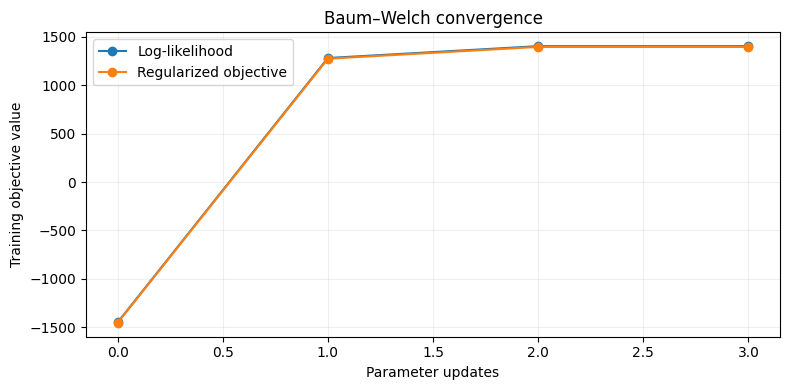

In [29]:
def train_hmm(training_sequences, starting_model,
              tolerance=1e-4, max_updates=200):
    model = {
        name: values.copy()
        for name, values in starting_model.items()
    }

    history = []
    converged = False

    for iteration in range(max_updates + 1):
        next_model, likelihood = baum_welch_step(
            training_sequences, model
        )

        objective = (
            likelihood
            + TRANSITION_PSEUDOCOUNT * np.log(model["A"]).sum()
        )

        if not np.isfinite(objective):
            raise ValueError("Training objective is not finite.")

        change = (
            objective - history[-1]["objective"]
            if history else np.nan
        )

        history.append({
            "update": iteration,
            "log_likelihood": likelihood,
            "objective": objective,
            "objective_change": change
        })

        if iteration > 0:
            if change < -1e-6:
                raise RuntimeError(
                    f"Objective decreased by {change:.6f}."
                )

            if abs(change) <= tolerance:
                converged = True
                break

        if iteration < max_updates:
            model = next_model

    return model, pd.DataFrame(history), converged


trained_model, training_history, converged = train_hmm(
    sequences["train"], initial_model
)

training_history.to_csv(
    REPORT / "training_history.csv", index=False
)

MODEL_FOLDER = PROJECT / "models"
MODEL_FOLDER.mkdir(parents=True, exist_ok=True)

np.savez(
    MODEL_FOLDER / "hmm_parameters.npz",
    **trained_model
)

print("Converged:", converged)
print("Parameter updates:", int(training_history["update"].iloc[-1]))
display(training_history.round(6))

fig, ax = plt.subplots(figsize=(8, 4))

for column, label in [
    ("log_likelihood", "Log-likelihood"),
    ("objective", "Regularized objective")
]:
    ax.plot(
        training_history["update"],
        training_history[column],
        marker="o",
        label=label
    )

ax.set_xlabel("Parameter updates")
ax.set_ylabel("Training objective value")
ax.set_title("Baum–Welch convergence")
ax.grid(alpha=0.2)
ax.legend()

fig.tight_layout()
fig.savefig(REPORT / "training_convergence.png", dpi=300)
plt.show()

### Training Results

Baum–Welch converged after three parameter updates. Training log-likelihood increased from −1452.662 to 1404.763, while the regularized objective increased from −1456.785 to 1397.077. The final objective change met the convergence tolerance. These results demonstrate convergence on training data; predictive performance requires separate validation.

In [30]:
training_confusion = np.zeros(
    (N_STATES, N_STATES), dtype=int
)

for sequence in sequences["train"]:
    predictions = viterbi(
        sequence["observations"], trained_model
    )

    for prediction in predictions:
        training_confusion[sequence["state"], prediction] += 1

training_accuracy = (
    np.trace(training_confusion) / training_confusion.sum()
)

assert np.isclose(trained_model["pi"].sum(), 1)
assert np.allclose(trained_model["A"].sum(axis=1), 1)
assert (trained_model["variances"] >= MIN_VARIANCE).all()

print("Training accuracy — sanity check only:",
      f"{training_accuracy:.3%}")

print("\nRows: actual activity | Columns: predicted activity")

display(pd.DataFrame(
    training_confusion,
    index=STATE_NAMES,
    columns=STATE_NAMES
))

print("Model probability and variance checks passed.")

Training accuracy — sanity check only: 100.000%

Rows: actual activity | Columns: predicted activity


,standing,walking,still,jumping
standing,70,0,0,0
walking,0,71,0,0
still,0,0,69,0
jumping,0,0,0,70


Model probability and variance checks passed.


### Training Sanity Check

Viterbi correctly decoded all 280 training windows, confirming that the trained states retain their intended activity labels. Initial and transition probabilities remain normalized, and variances satisfy the minimum constraint. This is a training check, not an independent performance result.

### Learned Transition Probabilities

The heatmap shows the probability of the next state given the current state. Recording boundaries were excluded from transition estimation. Because training recordings contain single activities, off-diagonal probabilities are influenced by regularization and should not be interpreted as measured real-world switching frequencies.

,standing,walking,still,jumping
standing,0.99503,0.00166,0.00166,0.00166
walking,0.00163,0.99511,0.00163,0.00163
still,0.00168,0.00168,0.99495,0.00168
jumping,0.00166,0.00166,0.00166,0.99503


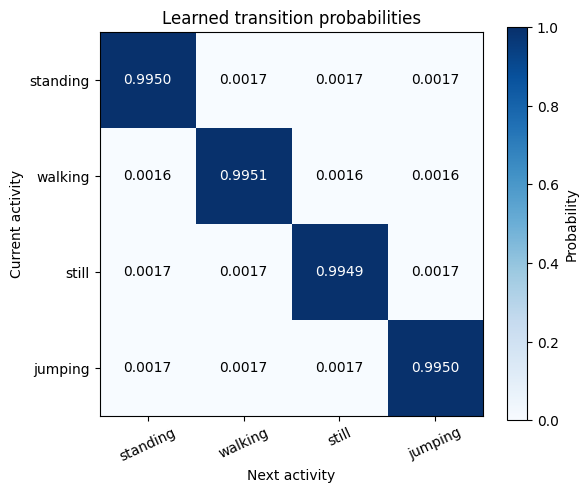

In [31]:
transition_table = pd.DataFrame(
    trained_model["A"],
    index=STATE_NAMES,
    columns=STATE_NAMES
)

transition_table.to_csv(REPORT / "learned_transitions.csv")
display(transition_table.round(5))

fig, ax = plt.subplots(figsize=(6, 5))

image = ax.imshow(
    trained_model["A"],
    cmap="Blues",
    vmin=0,
    vmax=1
)

ax.set_xticks(range(N_STATES), STATE_NAMES, rotation=25)
ax.set_yticks(range(N_STATES), STATE_NAMES)

for row in range(N_STATES):
    for column in range(N_STATES):
        probability = trained_model["A"][row, column]

        ax.text(
            column, row,
            f"{probability:.4f}",
            ha="center",
            va="center",
            color="white" if probability > 0.5 else "black"
        )

ax.set_xlabel("Next activity")
ax.set_ylabel("Current activity")
ax.set_title("Learned transition probabilities")

fig.colorbar(image, ax=ax, label="Probability")
fig.tight_layout()
fig.savefig(REPORT / "transition_heatmap.png", dpi=300)

plt.show()

### Transition Findings

Self-transition probabilities range from 0.99495 to 0.99511, reflecting strong persistence within single-activity training recordings. Off-diagonal probabilities are approximately 0.0016–0.0017 and are primarily supported by regularization. The matrix permits activity changes but does not establish their real-world frequencies or typical activity durations.

### Gaussian Emission Densities

Each plot shows the fitted marginal density of one transformed, standardized feature for each activity. Separation indicates how the feature supports classification; overlap indicates ambiguity. These are continuous probability densities, not class probabilities. Curve heights may exceed one.

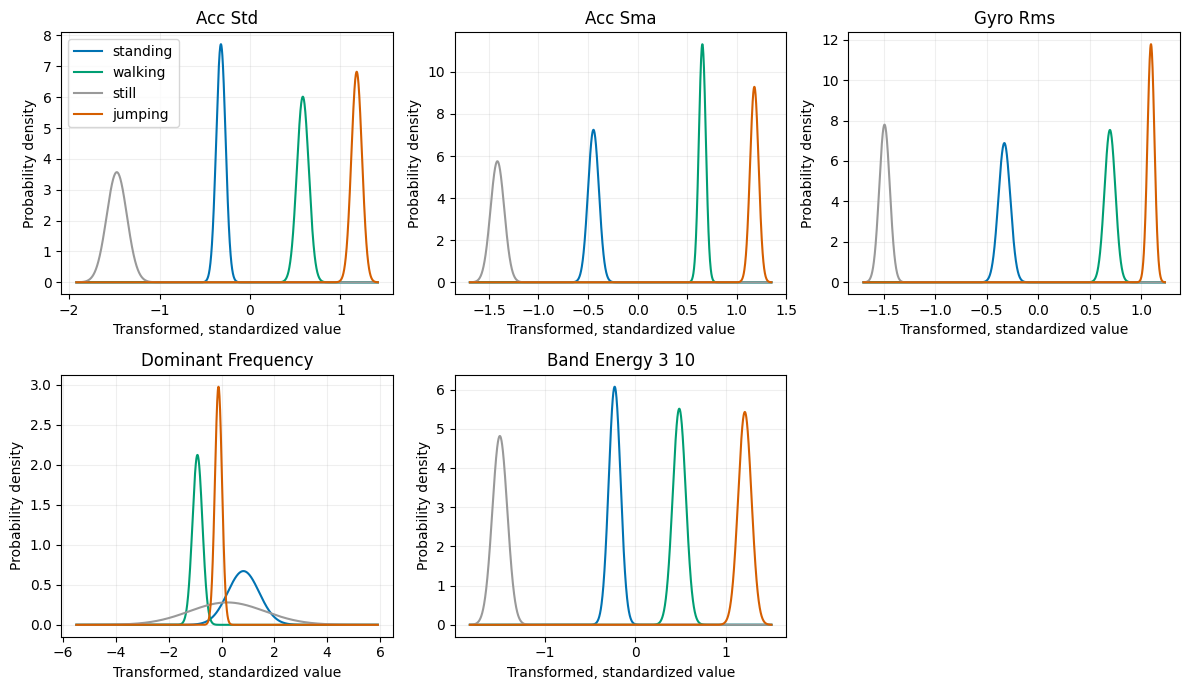

In [32]:
plot_colors = dict(zip(STATE_NAMES, activity_colors))

fig, axes = plt.subplots(2, 3, figsize=(12, 7))

for feature_index, ax in enumerate(axes.flat[:N_FEATURES]):
    means = trained_model["means"][:, feature_index]
    stds = np.sqrt(
        trained_model["variances"][:, feature_index]
    )

    x = np.linspace(
        np.min(means - 4 * stds),
        np.max(means + 4 * stds),
        2000
    )

    for state, activity in enumerate(STATE_NAMES):
        density = (
            np.exp(-0.5 * ((x - means[state]) / stds[state]) ** 2)
            / (stds[state] * np.sqrt(2 * np.pi))
        )

        ax.plot(
            x, density,
            color=plot_colors[activity],
            label=activity
        )

    ax.set_title(FEATURE_NAMES[feature_index].replace("_", " ").title())
    ax.set_xlabel("Transformed, standardized value")
    ax.set_ylabel("Probability density")
    ax.grid(alpha=0.2)

axes.flat[-1].set_visible(False)
axes.flat[0].legend()

fig.tight_layout()
fig.savefig(REPORT / "emission_densities.png", dpi=300)
plt.show()

pd.DataFrame(
    trained_model["means"],
    index=STATE_NAMES,
    columns=FEATURE_NAMES
).to_csv(REPORT / "emission_means.csv")

pd.DataFrame(
    trained_model["variances"],
    index=STATE_NAMES,
    columns=FEATURE_NAMES
).to_csv(REPORT / "emission_variances.csv")

### Emission Findings

The fitted acceleration variability, SMA, rotation intensity, and band-energy densities show clear separation between training activities. Dominant-frequency densities overlap more substantially. Narrow fitted distributions may limit robustness to new conditions, so training separation alone does not establish generalization.

## Validation Evaluation

We compare Viterbi decoding with emission-only classification on the 10 held-out development recordings. Emission-only classification selects the state with the highest Gaussian density for each window. Viterbi additionally uses initial and transition probabilities. This comparison tests whether sequence information changes predictions. Final test recordings remain unused.

In [33]:
def predict_sequences(items, model):
    rows = []

    for sequence in items:
        observations = sequence["observations"]

        emission_predictions = log_emissions(
            observations, model
        ).argmax(axis=1)

        hmm_predictions = viterbi(observations, model)

        for time, emission, hmm in zip(
            sequence["start_s"],
            emission_predictions,
            hmm_predictions
        ):
            rows.append({
                "recording_id": sequence["recording_id"],
                "start_s": time,
                "true_state": sequence["state"],
                "emission_state": int(emission),
                "hmm_state": int(hmm)
            })

    return pd.DataFrame(rows)


validation_predictions = predict_sequences(
    sequences["validation"], trained_model
)

comparison = pd.DataFrame([
    {
        "method": method,
        "correct_windows": int(
            validation_predictions[column]
            .eq(validation_predictions["true_state"]).sum()
        ),
        "total_windows": len(validation_predictions),
        "accuracy": validation_predictions[column]
        .eq(validation_predictions["true_state"]).mean()
    }
    for method, column in [
        ("Emission only", "emission_state"),
        ("HMM / Viterbi", "hmm_state")
    ]
])

validation_predictions.to_csv(
    REPORT / "validation_predictions.csv", index=False
)
comparison.to_csv(
    REPORT / "validation_method_comparison.csv", index=False
)

display(comparison)

print(
    "Windows where methods disagree:",
    int(
        validation_predictions["emission_state"]
        .ne(validation_predictions["hmm_state"]).sum()
    )
)

confusion = np.zeros((N_STATES, N_STATES), dtype=int)

np.add.at(
    confusion,
    (
        validation_predictions["true_state"].to_numpy(),
        validation_predictions["hmm_state"].to_numpy()
    ),
    1
)

print("\nValidation confusion matrix — actual rows, predicted columns:")
display(pd.DataFrame(
    confusion,
    index=STATE_NAMES,
    columns=STATE_NAMES
))

,method,correct_windows,total_windows,accuracy
0,Emission only,71,71,1.0
1,HMM / Viterbi,71,71,1.0


Windows where methods disagree: 0

Validation confusion matrix — actual rows, predicted columns:


,standing,walking,still,jumping
standing,22,0,0,0
walking,0,21,0,0
still,0,0,14,0
jumping,0,0,0,14


### Validation Findings

Emission-only classification and Viterbi both achieved 100% accuracy across 71 validation windows from 10 recordings. Their predictions were identical, so sequence decoding provided no measurable improvement on this validation set. The recordings share one participant and collection setting, limiting the scope of this result.

## Final Test Preparation

The five features, 2-second windows, 1-second step, normalization parameters, and trained model are now fixed. The four separate test recordings receive the same feature extraction and training-fitted transformations. Test results will not be used to revise this model.

In [34]:
np.savez(
    MODEL_FOLDER / "preprocessing_parameters.npz",
    feature_names=np.array(FEATURE_NAMES),
    log_features=np.array(LOG_FEATURES),
    log_offset=LOG_OFFSET,
    means=feature_means.to_numpy(),
    stds=feature_stds.to_numpy(),
    target_hz=TARGET_HZ,
    window_samples=WINDOW_SAMPLES,
    step_samples=STEP_SAMPLES,
    state_names=np.array(STATE_NAMES)
)

test_feature_rows = []

for path in sorted(TEST_CLEAN.glob("*.csv")):
    frame = pd.read_csv(path)

    for start in range(
        0, len(frame) - WINDOW_SAMPLES + 1, STEP_SAMPLES
    ):
        segment = frame.iloc[start:start + WINDOW_SAMPLES]

        test_feature_rows.append({
            "recording_id": path.stem,
            "activity": frame["activity"].iloc[0],
            "start_s": frame["seconds_elapsed"].iloc[start],
            **extract_features(segment)
        })

test_features = pd.DataFrame(test_feature_rows)

assert np.isfinite(test_features[FEATURE_NAMES].to_numpy()).all()

normalised_test = test_features.copy()
normalised_test[LOG_FEATURES] = np.log10(
    normalised_test[LOG_FEATURES] + LOG_OFFSET
)
normalised_test[FEATURE_NAMES] = (
    normalised_test[FEATURE_NAMES] - feature_means
) / feature_stds

assert np.isfinite(normalised_test[FEATURE_NAMES].to_numpy()).all()

sequences["test"] = []

for recording_id, group in normalised_test.groupby("recording_id"):
    group = group.sort_values("start_s")
    activity = group["activity"].iloc[0]

    sequences["test"].append({
        "recording_id": recording_id,
        "activity": activity,
        "state": STATE_INDEX[activity],
        "observations": group[FEATURE_NAMES].to_numpy(),
        "start_s": group["start_s"].to_numpy()
    })

normalised_test.to_csv(
    PROJECT / "data" / "normalised_test_features.csv",
    index=False
)

print("Model and preprocessing settings fixed.")
print("All test feature values are finite.")
print("\nTest windows per activity:")
print(test_features.groupby("activity").size().to_string())

Model and preprocessing settings fixed.
All test feature values are finite.

Test windows per activity:
activity
jumping     7
standing    7
still       7
walking     7


## Final Evaluation on Unseen Recordings

The fixed model is evaluated on four separately recorded test files, one per activity. Each contributes seven overlapping feature windows.

For each activity, sensitivity is TP/(TP+FN), specificity is TN/(TN+FP), and one-versus-rest accuracy is (TP+TN)/all windows. Overall multiclass accuracy is reported separately as the proportion of correctly classified windows. Metrics are reported as proportions from zero to one. These single-activity recordings assess recognition, not detection of real activity changes.

In [35]:
test_predictions = predict_sequences(
    sequences["test"], trained_model
)

test_confusion = np.zeros((N_STATES, N_STATES), dtype=int)

np.add.at(
    test_confusion,
    (
        test_predictions["true_state"].to_numpy(),
        test_predictions["hmm_state"].to_numpy()
    ),
    1
)

total = int(test_confusion.sum())
metric_rows = []

for state, activity in enumerate(STATE_NAMES):
    tp = int(test_confusion[state, state])
    fn = int(test_confusion[state].sum()) - tp
    fp = int(test_confusion[:, state].sum()) - tp
    tn = total - tp - fn - fp

    metric_rows.append({
        "activity": activity,
        "samples": tp + fn,
        "sensitivity": tp / (tp + fn),
        "specificity": tn / (tn + fp),
        "one_vs_rest_accuracy": (tp + tn) / total
    })

test_metrics = pd.DataFrame(metric_rows)
overall_accuracy = np.trace(test_confusion) / total

test_comparison = pd.DataFrame([
    {
        "method": method,
        "correct_windows": int(
            test_predictions[column]
            .eq(test_predictions["true_state"]).sum()
        ),
        "total_windows": total,
        "accuracy": test_predictions[column]
        .eq(test_predictions["true_state"]).mean()
    }
    for method, column in [
        ("Emission only", "emission_state"),
        ("HMM / Viterbi", "hmm_state")
    ]
])

confusion_table = pd.DataFrame(
    test_confusion,
    index=STATE_NAMES,
    columns=STATE_NAMES
)

test_predictions.to_csv(REPORT / "test_predictions.csv", index=False)
test_metrics.to_csv(REPORT / "test_metrics.csv", index=False)
test_comparison.to_csv(REPORT / "test_method_comparison.csv", index=False)
confusion_table.to_csv(REPORT / "test_confusion_matrix.csv")

print("Per-activity test metrics:")
display(test_metrics.round(4))

print(f"Overall multiclass accuracy: {overall_accuracy:.2%}")

print("\nMethod comparison:")
display(test_comparison)

print("\nConfusion matrix — actual rows, predicted columns:")
display(confusion_table)

Per-activity test metrics:


,activity,samples,sensitivity,specificity,one_vs_rest_accuracy
0,standing,7,1.0,1.0,1.0
1,walking,7,1.0,1.0,1.0
2,still,7,1.0,1.0,1.0
3,jumping,7,1.0,1.0,1.0


Overall multiclass accuracy: 100.00%

Method comparison:


,method,correct_windows,total_windows,accuracy
0,Emission only,28,28,1.0
1,HMM / Viterbi,28,28,1.0



Confusion matrix — actual rows, predicted columns:


,standing,walking,still,jumping
standing,7,0,0,0
walking,0,7,0,0
still,0,0,7,0
jumping,0,0,0,7


### Unseen-Test Findings

The HMM correctly classified all 28 scored windows across four separate test recordings, achieving 100% overall accuracy. Each activity had seven windows and sensitivity, specificity, and one-versus-rest accuracy of 1.00. Emission-only classification achieved the same result, so no additional accuracy benefit from Viterbi was observed.

These results support recognition of the four activities in this participant’s additional recordings. They do not establish performance across different participants, devices, or recording conditions. Overlapping windows are correlated, and single-activity tests do not evaluate transition detection. No activity was harder to classify by observed test error because all had zero errors.

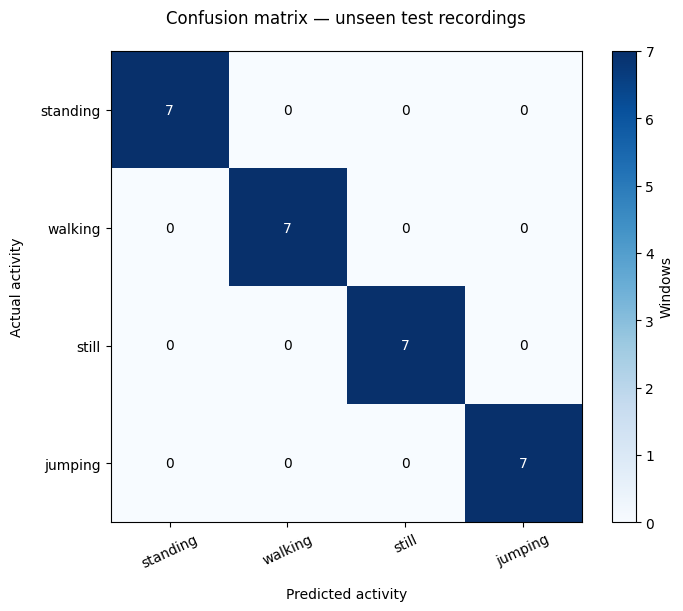

In [36]:
# Confusion matrix
fig, ax = plt.subplots(figsize=(7, 6), layout="constrained")

image = ax.imshow(
    test_confusion,
    cmap="Blues",
    vmin=0,
    vmax=test_confusion.max()
)

ax.set_xticks(range(N_STATES), STATE_NAMES, rotation=25)
ax.set_yticks(range(N_STATES), STATE_NAMES)

for row in range(N_STATES):
    for column in range(N_STATES):
        count = test_confusion[row, column]

        ax.text(
            column, row, str(count),
            ha="center",
            va="center",
            color="white" if count > test_confusion.max() / 2 else "black"
        )

ax.set_xlabel("Predicted activity", labelpad=12)
ax.set_ylabel("Actual activity", labelpad=12)
ax.set_title("Confusion matrix — unseen test recordings", pad=20)

fig.colorbar(image, ax=ax, label="Windows", pad=0.05)
fig.savefig(
    REPORT / "test_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

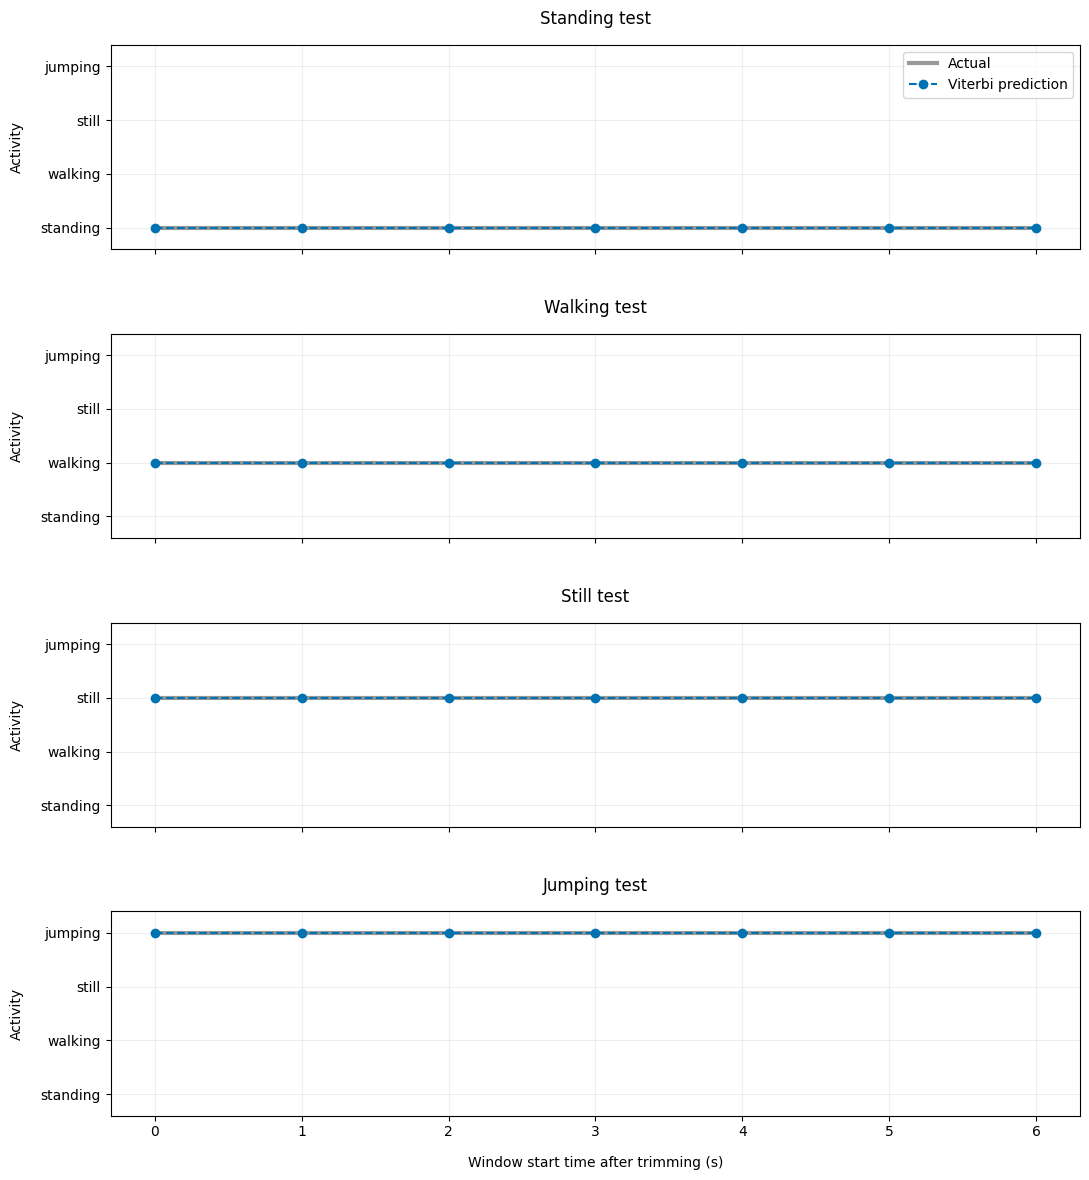

In [37]:
# Decoded sequences
fig, axes = plt.subplots(
    4, 1,
    figsize=(11, 12),
    sharex=True,
    layout="constrained"
)

fig.set_constrained_layout_pads(
    w_pad=0.15,
    h_pad=0.2,
    hspace=0.15
)

for ax, activity in zip(axes, ACTIVITIES):
    group = test_predictions.loc[
        test_predictions["recording_id"].eq(f"{activity}_test")
    ].sort_values("start_s")

    ax.step(
        group["start_s"],
        group["true_state"],
        where="post",
        color="black",
        linewidth=3,
        alpha=0.4,
        label="Actual"
    )

    ax.plot(
        group["start_s"],
        group["hmm_state"],
        "o--",
        color="#0072B2",
        label="Viterbi prediction"
    )

    ax.set_yticks(range(N_STATES), STATE_NAMES)
    ax.set_ylim(-0.4, N_STATES - 0.6)
    ax.set_title(f"{activity.capitalize()} test", pad=15)
    ax.set_ylabel("Activity", labelpad=12)
    ax.grid(alpha=0.2)

axes[0].legend(loc="upper right")
axes[-1].set_xlabel(
    "Window start time after trimming (s)",
    labelpad=12
)

fig.savefig(
    REPORT / "test_decoded_sequences.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

## Continuous Recording: Qualitative Evaluation

An additional continuous recording contains the confirmed activity order: still, standing, walking, then jumping. The fixed model will decode this recording to demonstrate predicted activity changes.

Exact activity boundaries were not independently documented. Therefore, this recording will support qualitative analysis only; no accuracy or transition-timing scores will be calculated. The four labelled test recordings remain the source of reported performance metrics.

In [38]:
CONTINUOUS_ZIP = Path("/content/Continuous_Recording.zip")
CONTINUOUS_RAW = PROJECT / "data" / "continuous_original"

assert CONTINUOUS_ZIP.exists(), "Upload Continuous_Recording.zip first."

with ZipFile(CONTINUOUS_ZIP) as archive:
    for name in archive.namelist():
        target = (CONTINUOUS_RAW / name).resolve()

        if not target.is_relative_to(CONTINUOUS_RAW.resolve()):
            raise ValueError("The ZIP contains an invalid file path.")

    archive.extractall(CONTINUOUS_RAW)

continuous_folders = sorted(
    folder for folder in CONTINUOUS_RAW.iterdir()
    if folder.is_dir()
    and (folder / "Accelerometer.csv").is_file()
    and (folder / "Gyroscope.csv").is_file()
)

assert len(continuous_folders) == 1, "Expected one recording folder."

CONTINUOUS_FOLDER = continuous_folders[0]

print("Recording:", CONTINUOUS_FOLDER.name)

for sensor in ["Accelerometer.csv", "Gyroscope.csv"]:
    frame = pd.read_csv(CONTINUOUS_FOLDER / sensor)
    elapsed = frame["seconds_elapsed"]

    print(
        f"{sensor}: {len(frame)} rows, "
        f"{elapsed.iloc[-1] - elapsed.iloc[0]:.3f} seconds"
    )

Recording: continous-recording-2026-10-28_20-15-49
Accelerometer.csv: 2161 rows, 43.314 seconds
Gyroscope.csv: 2162 rows, 43.334 seconds


### Continuous Recording Preprocessing

The continuous recording receives the established 0.3-second start and end trims and 50 Hz sensor alignment. Internal activity transitions are preserved. No activity labels are assigned because exact boundaries are unknown.

In [39]:
continuous_sensors = {
    name: pd.read_csv(CONTINUOUS_FOLDER / name)
    for name in SENSOR_FILES
}

start = max(
    frame["seconds_elapsed"].iloc[0]
    for frame in continuous_sensors.values()
) + TRIM_SECONDS

end = min(
    frame["seconds_elapsed"].iloc[-1]
    for frame in continuous_sensors.values()
) - TRIM_SECONDS

sample_count = int(np.floor((end - start) * TARGET_HZ)) + 1
timeline = start + np.arange(sample_count) / TARGET_HZ

acceleration = continuous_sensors["Accelerometer.csv"]
origin_ns = int(acceleration["time"].iloc[0])
origin_s = acceleration["seconds_elapsed"].iloc[0]

continuous_cleaned = pd.DataFrame({
    "timestamp_ns": origin_ns + np.rint(
        (timeline - origin_s) * 1e9
    ).astype("int64"),
    "seconds_elapsed": np.arange(sample_count) / TARGET_HZ
})

for filename, prefix in [
    ("Accelerometer.csv", "accel"),
    ("Gyroscope.csv", "gyro")
]:
    frame = continuous_sensors[filename]

    for axis in ["x", "y", "z"]:
        continuous_cleaned[f"{prefix}_{axis}"] = np.interp(
            timeline,
            frame["seconds_elapsed"],
            frame[axis]
        )

assert np.isfinite(
    continuous_cleaned[sensor_columns].to_numpy()
).all()

assert np.allclose(
    np.diff(continuous_cleaned["seconds_elapsed"]),
    1 / TARGET_HZ,
    rtol=0,
    atol=1e-9
)

assert (
    np.diff(continuous_cleaned["timestamp_ns"]) == 20_000_000
).all()

continuous_cleaned.to_csv(
    PROJECT / "data" / "continuous_cleaned.csv",
    index=False
)

print("Aligned rows:", len(continuous_cleaned))
print(
    "Retained duration:",
    f"{continuous_cleaned['seconds_elapsed'].iloc[-1]:.2f} seconds"
)
print("Numeric and timing checks passed.")

Aligned rows: 2136
Retained duration: 42.70 seconds
Numeric and timing checks passed.


### Continuous Sequence Decoding

We apply the established 2-second windows, 1-second step, five features, and training-fitted normalization. The unchanged HMM decodes all windows, including those spanning activity changes. Predicted changes are qualitative estimates; window start times are not verified transition times.

In [40]:
continuous_rows = []

for start in range(
    0,
    len(continuous_cleaned) - WINDOW_SAMPLES + 1,
    STEP_SAMPLES
):
    segment = continuous_cleaned.iloc[
        start:start + WINDOW_SAMPLES
    ]

    continuous_rows.append({
        "start_s": continuous_cleaned["seconds_elapsed"].iloc[start],
        **extract_features(segment)
    })

continuous_features = pd.DataFrame(continuous_rows)
assert np.isfinite(
    continuous_features[FEATURE_NAMES].to_numpy()
).all()

continuous_normalised = continuous_features.copy()

continuous_normalised[LOG_FEATURES] = np.log10(
    continuous_normalised[LOG_FEATURES] + LOG_OFFSET
)

continuous_normalised[FEATURE_NAMES] = (
    continuous_normalised[FEATURE_NAMES] - feature_means
) / feature_stds

observations = continuous_normalised[FEATURE_NAMES].to_numpy()
assert np.isfinite(observations).all()

continuous_predictions = continuous_features[["start_s"]].copy()
continuous_predictions["window_end_s"] = (
    continuous_predictions["start_s"] + WINDOW_SECONDS
)

continuous_predictions["predicted_state"] = viterbi(
    observations, trained_model
)

continuous_predictions["predicted_activity"] = [
    STATE_NAMES[state]
    for state in continuous_predictions["predicted_state"]
]

continuous_predictions.to_csv(
    REPORT / "continuous_predictions.csv",
    index=False
)

changed = continuous_predictions["predicted_activity"].ne(
    continuous_predictions["predicted_activity"].shift()
)

predicted_changes = continuous_predictions.loc[
    changed,
    ["start_s", "window_end_s", "predicted_activity"]
]

print("Decoded windows:", len(continuous_predictions))
print("\nFirst window of each predicted activity run:")
display(predicted_changes)

Decoded windows: 41

First window of each predicted activity run:


,start_s,window_end_s,predicted_activity
0,0.0,2.0,still
11,11.0,13.0,standing
12,12.0,14.0,walking
15,15.0,17.0,standing
22,22.0,24.0,walking
32,32.0,34.0,jumping


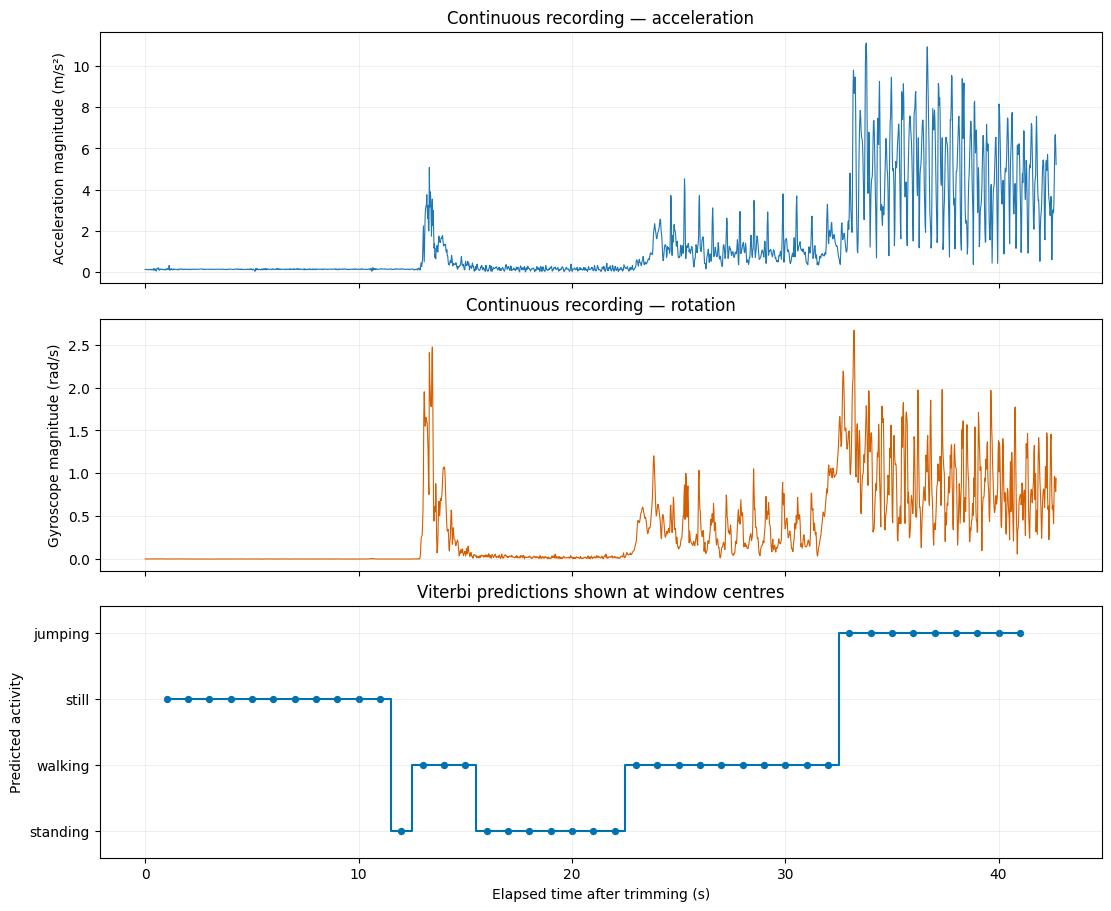

In [41]:
elapsed = continuous_cleaned["seconds_elapsed"]

acceleration_magnitude = np.linalg.norm(
    continuous_cleaned[["accel_x", "accel_y", "accel_z"]],
    axis=1
)

rotation_magnitude = np.linalg.norm(
    continuous_cleaned[["gyro_x", "gyro_y", "gyro_z"]],
    axis=1
)

window_centres = (
    continuous_predictions["start_s"] + WINDOW_SECONDS / 2
)

fig, axes = plt.subplots(
    3, 1,
    figsize=(11, 9),
    sharex=True,
    layout="constrained"
)

axes[0].plot(elapsed, acceleration_magnitude, linewidth=0.8)
axes[0].set_title("Continuous recording — acceleration")
axes[0].set_ylabel("Acceleration magnitude (m/s²)")

axes[1].plot(
    elapsed, rotation_magnitude,
    color="#D55E00",
    linewidth=0.8
)
axes[1].set_title("Continuous recording — rotation")
axes[1].set_ylabel("Gyroscope magnitude (rad/s)")

axes[2].step(
    window_centres,
    continuous_predictions["predicted_state"],
    where="mid",
    color="#0072B2"
)
axes[2].scatter(
    window_centres,
    continuous_predictions["predicted_state"],
    color="#0072B2",
    s=18
)

axes[2].set_yticks(range(N_STATES), STATE_NAMES)
axes[2].set_ylim(-0.4, N_STATES - 0.6)
axes[2].set_title("Viterbi predictions shown at window centres")
axes[2].set_ylabel("Predicted activity")
axes[2].set_xlabel("Elapsed time after trimming (s)")

for ax in axes:
    ax.grid(alpha=0.2)

fig.savefig(
    REPORT / "continuous_signal_and_predictions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Continuous Decoding Findings

The continuous recording produces predictions for all four activities. A brief walking run near 13 seconds coincides with a movement burst that the participant identifies as phone handling. This demonstrates a limitation: handling movements can resemble an activity and receive a walking label. Later predictions progress through standing, walking, and jumping. Exact boundaries were not independently documented, so no accuracy or transition-timing scores are reported.

## Processing Workflow

The diagram summarizes preprocessing, recording-level separation, feature extraction, training-only normalization, model fitting, and evaluation. Labelled test recordings provide quantitative metrics; the continuous recording provides qualitative transition analysis.

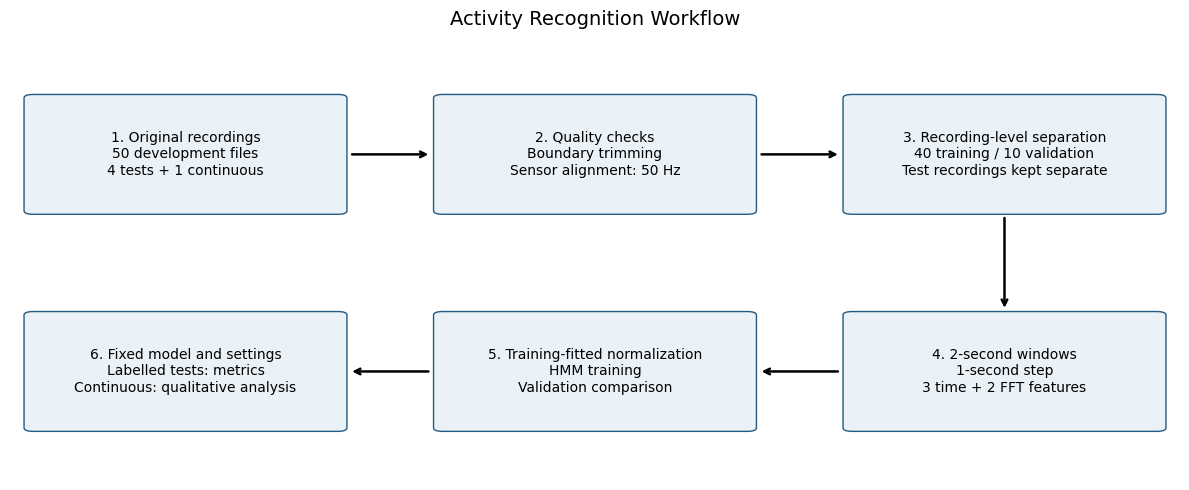

In [42]:
from matplotlib.patches import FancyBboxPatch

labels = [
    "Original recordings\n50 development files\n4 tests + 1 continuous",
    "Quality checks\nBoundary trimming\nSensor alignment: 50 Hz",
    "Recording-level separation\n40 training / 10 validation\nTest recordings kept separate",
    "2-second windows\n1-second step\n3 time + 2 FFT features",
    "Training-fitted normalization\nHMM training\nValidation comparison",
    "Fixed model and settings\nLabelled tests: metrics\nContinuous: qualitative analysis"
]

positions = [
    (0.15, 0.75), (0.50, 0.75), (0.85, 0.75),
    (0.85, 0.25), (0.50, 0.25), (0.15, 0.25)
]

fig, ax = plt.subplots(figsize=(12, 5))
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.axis("off")

for number, (label, (x, y)) in enumerate(
    zip(labels, positions), start=1
):
    box = FancyBboxPatch(
        (x - 0.13, y - 0.13),
        0.26, 0.26,
        boxstyle="round,pad=0.008",
        facecolor="#EAF2F8",
        edgecolor="#245A81"
    )
    ax.add_patch(box)
    ax.text(
        x, y, f"{number}. {label}",
        ha="center", va="center", fontsize=10
    )

arrows = [
    ((0.29, 0.75), (0.36, 0.75)),
    ((0.64, 0.75), (0.71, 0.75)),
    ((0.85, 0.61), (0.85, 0.39)),
    ((0.71, 0.25), (0.64, 0.25)),
    ((0.36, 0.25), (0.29, 0.25))
]

for start, end in arrows:
    ax.annotate(
        "", xy=end, xytext=start,
        arrowprops={"arrowstyle": "->", "lw": 1.8}
    )

ax.set_title("Activity Recognition Workflow", fontsize=14, pad=15)
fig.tight_layout()
fig.savefig(REPORT / "processing_workflow.png", dpi=300)
plt.show()

### HMM State–Observation Structure

Each hidden state represents an activity. Transition probabilities connect successive states, while Gaussian emission densities connect each state to its observed feature vector. Initial probabilities describe the starting state. Each observation contains five transformed, standardized features.

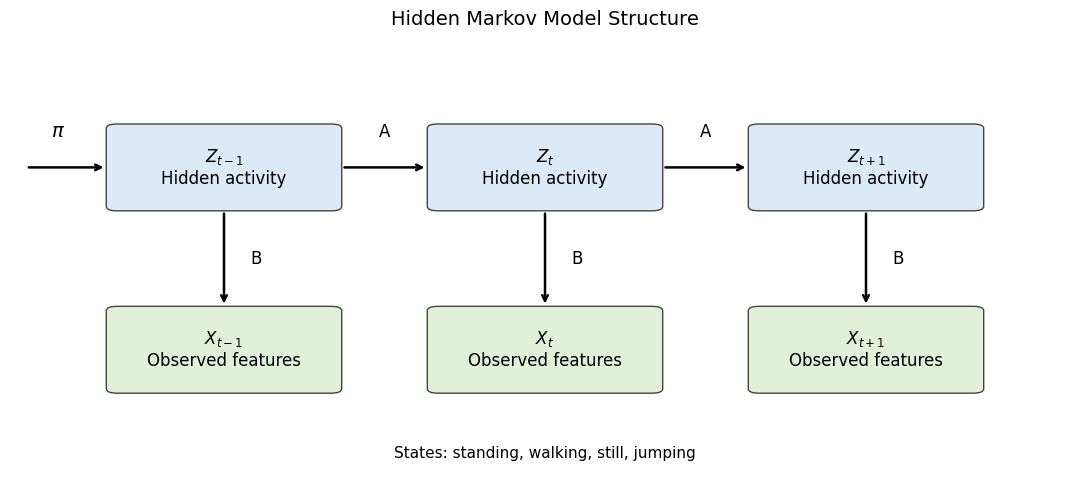

In [43]:
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(11, 5))
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.axis("off")

positions = [0.20, 0.50, 0.80]
times = ["t-1", "t", "t+1"]

for x, time in zip(positions, times):
    for y, symbol, description, color in [
        (0.72, "Z", "Hidden activity", "#DCEAF7"),
        (0.30, "X", "Observed features", "#E2F0D9")
    ]:
        box = FancyBboxPatch(
            (x - 0.10, y - 0.09),
            0.20, 0.18,
            boxstyle="round,pad=0.01",
            facecolor=color,
            edgecolor="#444444"
        )
        ax.add_patch(box)

        ax.text(
            x, y,
            f"${symbol}_{{{time}}}$\n{description}",
            ha="center", va="center", fontsize=12
        )

    ax.annotate(
        "", xy=(x, 0.40), xytext=(x, 0.62),
        arrowprops={"arrowstyle": "->", "lw": 1.8}
    )
    ax.text(
        x + 0.025, 0.51, "B",
        fontsize=12, va="center"
    )

for left, right in zip(positions[:-1], positions[1:]):
    ax.annotate(
        "", xy=(right - 0.11, 0.72),
        xytext=(left + 0.11, 0.72),
        arrowprops={"arrowstyle": "->", "lw": 1.8}
    )
    ax.text(
        (left + right) / 2, 0.79,
        "A", ha="center", fontsize=12
    )

ax.annotate(
    "", xy=(0.09, 0.72), xytext=(0.015, 0.72),
    arrowprops={"arrowstyle": "->", "lw": 1.8}
)
ax.text(0.045, 0.79, r"$\pi$", ha="center", fontsize=14)

ax.text(
    0.5, 0.05,
    "States: standing, walking, still, jumping",
    ha="center", fontsize=11
)

ax.set_title("Hidden Markov Model Structure", fontsize=14, pad=15)

fig.tight_layout()
fig.savefig(
    REPORT / "hmm_structure.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

## Discussion and Conclusion

### Activity Recognition

All four activities were classified correctly in the labelled test recordings, so test errors do not identify an easiest or hardest activity. Training plots show strong separation in movement-intensity features, while dominant frequency overlaps more. The continuous recording exposes a practical difficulty: participant-confirmed phone handling received brief walking predictions.

### Transition Behavior

Self-transition probabilities are approximately 0.995, reflecting persistence within single-activity training recordings. Switching probabilities are mainly supported by regularization rather than observed activity changes. These estimates should not be interpreted as typical real-world switching frequencies. The continuous recording demonstrates predicted changes, but undocumented boundaries prevent transition-accuracy measurement.

### Sensor Quality and Sampling

Measured sampling rates were approximately 49.876 Hz. Interpolation aligned the sensors on a common 50 Hz timeline. Boundary inspection identified handling disturbances, leading to standard trimming and one documented recording-specific adjustment. No large timing gaps were found. We did not experimentally isolate the effect of sampling rate on accuracy, and all recordings used one phone.

### Generalization and Limitations

Both emission-only classification and Viterbi achieved 100% validation accuracy across 71 windows and 100% test accuracy across 28 windows. Therefore, these results show no measurable accuracy benefit from sequence decoding. The test set contains only four short recordings from one participant, and overlapping windows are correlated. Performance across other people, devices, phone positions, and environments remains untested. The diagonal Gaussian model also approximates potentially correlated features as conditionally independent.

### Improvements

Future work should collect independently timed continuous training and test recordings, include phone-handling movements, and vary participants, phone positions, devices, and environments. A transition or handling state could help distinguish repositioning from the target activities. Alternative features and window sizes should be assessed on development data before a new untouched test evaluation.

### Conclusion

The implemented HMM converged and correctly recognized all scored windows in the four labelled test recordings. The continuous recording demonstrated activity changes but also revealed ambiguity during phone handling. The results support feasibility in this limited collection setting, while broader generalization and reliable transition detection require additional evidence.

In [44]:
import shutil
from google.colab import files

backup_path = shutil.make_archive(
    "/content/activity_hmm_project",
    "zip",
    root_dir=PROJECT.parent,
    base_dir=PROJECT.name
)

files.download(backup_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>